# Case study: which trade action for which beer outlet?

A beer brand sells to 20,000 retail outlets. Every month it can give each outlet one
trade action (an **arm**): nothing (`control`), a `zalo_message`, a `price_promo`,
a `display_kit` or a `rep_visit`. Actions cost money, and display kits and rep visits are
limited per region per month. This notebook estimates, for every outlet-month, how many extra cases each arm brings, chooses the arm
with the best net margin within the limits, and checks the choice against the current
business-as-usual (BAU) rule.

**The data is synthetic.** Every name, cost, capacity and figure is illustrative. Because
the data is simulated, the true effect of every arm on every row is known, so the last
parts can grade the model against the truth. Real projects do not have that luxury.

**This notebook is published already executed.** It calls a private modelling library
(`auto_uplift_multi_arms`, imported as `aum`) that is not part of this repository, so it
cannot be re-run from here. Every output is saved in the cells and in `outputs/`. The
method behind the library is described in `../method/README.md`; the code cells show which
step is called and with which main settings.

Two reports are built from this notebook's outputs: `case_study_technical.pdf` walks through it part by
part with the same part numbers and titles; `case_study_business.pdf` is the short version for business readers.

| Part | Title |
|---|---|
| 1 | Data |
| 2 | Ground truth (synthetic data only) |
| 3 | Train / test split |
| 4 | Feature filter |
| 5 | Tuning: learner and LightGBM parameters |
| 6 | Learners compared on shared nuisances |
| 7 | Policies: best arm, capacity, share sweep |
| 8 | Policy value on the test outlets |
| 9 | Uplift curve and Qini per arm |
| 10 | Calibration |
| 11 | What drives the effects and the decisions |
| 12 | Robustness checks |
| 13 | Model against the truth |
| 14 | Reproduce |

Helper code (data loading, export of figures and numbers, truth comparisons) lives in
`case_study_helpers.py` next to this notebook, so the cells here stay short. Every
figure, table and number used by the reports is written to `outputs/` while the notebook runs.

**Short words used in outputs.** VND: Vietnamese dong, money unit (60,000 VND gross margin per case);
`mVND`: million VND. DR: doubly robust; a *DR observed* effect is the mean DR score difference of a
group of rows, the data's own estimate of the effect there. ESS: effective sample size of the DR
weights (small means weak overlap). TPE: tree-structured Parzen estimator, the tuner's search method.
Cramér's V: association between two categorical columns (0 to 1). `auuc`: area under the uplift curve.
Regret: true net value of the true best arm minus that of the chosen arm (synthetic data only).
Learners: `t` (T-learner, difference of two outcome models), `x` (X-learner), `dr` (DR-learner,
regression of the DR score difference); CATE: conditional average treatment effect, the effect for
one row. Propensity `e_k`: probability that a row got arm k; `e_p01`/`e_p05`: its 1st and 5th
percentiles. Cross-fitting / out of fold: every row is predicted by models fitted without its
outlet. `ess_share`: ESS divided by the number of rows that received the arm. `ate`: DR net gain (VND per outlet-month) if every row got
the arm. `mae`: mean absolute error. Isotonic: a monotone step function fitted to the data. `pdp`:
partial dependence plot.
The PDF's Definitions section explains every other term.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import auto_uplift_multi_arms as aum
import case_study_helpers as h

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("once", category=RuntimeWarning)   # identical library warnings are shown once
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # no scientific notation
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 160)
X = h.Exporter()            # saves figures, tables and numbers to outputs/ for the reports
print("auto_uplift_multi_arms", aum.__version__)
print("cross-fitting folds:", h.N_FOLDS, "| propensity clip in DR scores:", h.PROPENSITY_CLIP,
      "| propensity floor of the policies:", h.PROPENSITY_FLOOR)
print("LightGBM settings, learners:", h.BASE_PARAMS)
print("LightGBM settings, referee: ", h.REFEREE_PARAMS)

auto_uplift_multi_arms 0.2.0
cross-fitting folds: 3 | propensity clip in DR scores: 0.01 | propensity floor of the policies: 0.02
LightGBM settings, learners: {'n_estimators': 300, 'learning_rate': 0.05, 'early_stopping': True, 'n_jobs': 5, 'verbose': -1}
LightGBM settings, referee:  {'n_estimators': 300, 'learning_rate': 0.05, 'early_stopping': True, 'num_leaves': 15, 'min_child_samples': 1000, 'n_jobs': 5, 'verbose': -1}


## Part 1. Data

**Purpose.** Load the synthetic panel and describe it: what one row is, the period, how
many outlets and rows, how arms were assigned and what the outcome is.

**Inputs.** `h.load_data()`, which calls `make_beer_promo_data(random_state=42)` from `data_gen/`
(rules in `data_rules.md`) and adds `month_index`.

**What to look at.** Rows per arm, the share of rows from the randomised trade test, and
the last table: a naive comparison of outcomes by arm is biased because the BAU rule gives
arms to particular outlets.

In [2]:
df, truth, meta = h.load_data()                   # panel, true effects, metadata
FEATURES = h.features_of(df)                         # every column except ids, arm, rule_arm, design flag, outcomes
COST, VALUE, LABELS = meta["cost"], meta["value_per_outcome"], meta["arm_labels"]
print(f"{len(df):,} rows = {df.outlet_id.nunique():,} outlets x {df.month.nunique()} months "
      f"({meta['months'][0]} to {meta['months'][-1]}); Tet month {meta['tet_month'][0]}")
print(f"share of rows in the randomised trade test: {df.in_trade_test.mean():.1%}")
print("cost per outlet-month (VND):", {LABELS[k]: v for k, v in COST.items()})
print(f"value_per_outcome: {VALUE:,} VND gross margin per case")
X.num(n_rows=len(df), n_outlets=df.outlet_id.nunique(), n_months=df.month.nunique(),
      month_first=meta["months"][0], month_last=meta["months"][-1], tet_month=meta["tet_month"][0],
      randomised_share=df.in_trade_test.mean(), mean_cases=df.cases_ordered.mean(),
      zero_share=(df.cases_ordered == 0).mean(), median_cases_if_order=df.loc[df.cases_ordered > 0, "cases_ordered"].median(),
      n_features=len(FEATURES), cost=COST, value_per_outcome=VALUE, arm_labels=LABELS,
      arm_descriptions=meta["arm_descriptions"], capacity_full=meta["capacity"])
df.head(3).T

120,000 rows = 20,000 outlets x 6 months (2026-01 to 2026-06); Tet month 2026-02
share of rows in the randomised trade test: 70.0%
cost per outlet-month (VND): {'control': 0, 'zalo_message': 2000, 'price_promo': 120000, 'display_kit': 400000, 'rep_visit': 150000}
value_per_outcome: 60,000 VND gross margin per case


,0,1,2
outlet_id,1,2,3
month,2026-01-01 00:00:00,2026-01-01 00:00:00,2026-01-01 00:00:00
region,South,Central,Mekong
province,south_01,central_02,mekong_03
channel,on_trade_restaurant,off_trade_grocery,modern_trade
outlet_size,medium,small,medium
n_coolers,0,0,1
seating_capacity,62.0000,NaN,NaN
vol_last_1m,39.4000,7.9000,109.5000
vol_avg_3m,35.2000,5.2000,128.1000


In [3]:
X.table(h.rows_per_arm(df, meta), "rows_per_arm",
        "Rows per arm in the full panel: count, share, share coming from the randomised trade test, mean cases ordered.",
        "Part 1, h.rows_per_arm")

,arm,label,rows,share_of_rows_%,from_trade_test_%,mean_cases_ordered
0,0,control,35429,29.5000,50.5000,49.8500
1,1,zalo_message,18872,15.7000,94.4000,50.0200
2,2,price_promo,26381,22.0000,68.7000,50.1000
3,3,display_kit,19330,16.1000,78.1000,35.9900
4,4,rep_visit,19988,16.7000,75.5000,46.5500


In [4]:
cap = pd.DataFrame(meta["capacity"]).rename(columns=LABELS)
cap.index.name = "region"
X.table(cap.reset_index().assign(outlets=df.groupby("region").outlet_id.nunique().reindex(cap.index).to_numpy()),
        "capacity_full", "Capacity per region and month for the whole outlet base (outlets per month).", "Part 1, meta['capacity']")

,region,display_kit,rep_visit,outlets
0,North,360,480,6015
1,Central,180,240,2983
2,Highlands,120,160,1947
3,South,360,490,6083
4,Mekong,180,240,2972


In [5]:
dd = h.data_dictionary(df)
X.table(dd, "data_dictionary", "Data dictionary: every column of the panel.", "Part 1, h.data_dictionary")

,column,type,meaning,unit,missing_%,example
0,outlet_id,int,Outlet identifier.,id,0.0000,1
1,month,date,First day of the month.,date,0.0000,2026-01-01
2,region,category (5),"Region: North, Central, Highlands, South, Mekong.",,0.0000,South
3,province,category (20),Province code inside the region (20 levels).,,0.0000,south_01
4,channel,category (5),"Outlet type: bar, restaurant, grocery, minimart, modern trade.",,0.0000,on_trade_restaurant
5,outlet_size,category (3),small / medium / large.,,0.0000,medium
6,n_coolers,int,Coolers at the outlet.,count,0.0000,0
7,seating_capacity,float,"Seats; on-trade only, missing elsewhere.",seats,60.3000,62.0000
8,vol_last_1m,float,Cases ordered last month.,cases,0.0000,39.4000
9,vol_avg_3m,float,Mean cases ordered over the last 3 months.,cases,0.0000,35.2000


In [6]:
nv = h.naive_vs_true(df, truth, meta)
X.num(naive=nv.set_index("label").to_dict(orient="index"))
X.table(nv, "naive_vs_true",
        "Average effect in cases per outlet-month: naive difference of means on all rows, difference on trade-test rows "
        "(outlets where the arm is allowed), and the true average effect.", "Part 1, h.naive_vs_true")

,arm,label,naive_difference_all_rows,difference_trade_test_rows,true_average_effect
0,1,zalo_message,0.1700,-0.0600,0.4700
1,2,price_promo,0.2500,2.5000,3.5500
2,3,display_kit,-13.8600,4.6500,4.3800
3,4,rep_visit,-3.3000,5.8100,6.2300


**Takeaway.** 120,000 outlet-months (20,000 outlets x 6 months). 70% of rows come from the randomised trade test, 30% from the BAU rule. Raw comparisons by arm are biased by the BAU rule: on all rows a display kit seems to lose 13.9 cases, while its true average effect is +4.4.

## Part 2. Ground truth (synthetic data only)

**Purpose.** Show the true effect structure the generator used, so the model can be judged
against it later. A real project does not have this table.

**Inputs.** `truth`: true effect `tau_k` (cases), true net value `net_value_k`
(VND = 60,000 x tau_k - cost_k) and `true_best_arm` for every row.

**What to look at.** The true best arm differs by channel; the price promo loses money
where our brand share is high; the oracle (true best arm everywhere) sets the ceiling.

In [7]:
te = h.true_effects_by(df, truth, meta, "channel")
X.table(te, "true_effects_by_channel",
        "True mean effect (tau, cases per outlet-month) and true mean net value (net, VND per outlet-month) of each arm, by channel.",
        "Part 2, h.true_effects_by")

,channel,rows,tau_zalo_message,tau_price_promo,tau_display_kit,tau_rep_visit,net_zalo_message,net_price_promo,net_display_kit,net_rep_visit
0,modern_trade,12138,0.4700,5.1800,2.2400,1.1300,26100,190900,-265800,-82500
1,off_trade_grocery,38532,0.4200,2.8600,6.1200,3.8100,23400,51600,-32800,78800
2,off_trade_minimart,21738,0.4400,3.4700,8.8800,4.8300,24200,88200,133000,139600
3,on_trade_bar,21630,0.4500,3.7200,0.4100,9.1900,24900,103000,-375400,401200
4,on_trade_restaurant,25962,0.5700,3.7500,1.3200,8.5300,32500,104800,-321000,361700


In [8]:
tb = h.true_best_mix(df, truth, meta, "channel")
X.table(tb, "true_best_by_channel", "Share of rows (%) whose true best arm is each arm, by channel.", "Part 2, h.true_best_mix")

true_best_arm,channel,control,zalo_message,price_promo,display_kit,rep_visit
0,modern_trade,4.6000,13.2000,81.7000,0.0000,0.4000
1,off_trade_grocery,7.1000,12.2000,21.7000,34.8000,24.3000
2,off_trade_minimart,4.3000,6.2000,18.2000,47.1000,24.2000
3,on_trade_bar,0.0000,1.3000,14.3000,0.0000,84.4000
4,on_trade_restaurant,0.0000,2.7000,18.2000,0.0000,79.1000
5,all rows,3.5000,7.2000,25.0000,19.7000,44.5000


In [9]:
ps = h.promo_by_share(df, truth)
X.table(ps, "promo_by_share_truth",
        "True effect and true net value of price_promo by band of brand_share_est (rows with a known share).",
        "Part 2, h.promo_by_share")

,brand_share_est,rows,true_effect_cases,true_net_value_vnd,share_rows_promo_loses_%
0,0.0 to 0.2,4914,7.8400,350600,0.4000
1,0.2 to 0.3,11316,6.2700,256200,0.9000
2,0.3 to 0.4,18090,4.9800,178800,2.1000
3,0.4 to 0.5,22944,3.6900,101600,12.1000
4,0.5 to 0.6,22488,2.6900,41600,36.9000
5,0.6 to 0.7,16668,1.8900,-6700,65.0000
6,0.7 to 0.8,9888,1.2500,-44700,86.9000
7,0.8 to 1.0,3990,0.7800,-72900,96.2000


In [10]:
net_all = h.true_net(truth)
bau_true = h.true_value(net_all, df.rule_arm.to_numpy())
oracle_true = net_all.max(1).mean()
X.num(true_bau_full=bau_true, true_oracle_full=oracle_true,
      true_best_share=truth.true_best_arm.map(LABELS).value_counts(normalize=True).to_dict(),
      harmful_share={LABELS[k]: (truth[f"net_value_{k}"] < 0).mean() for k in range(1, 5)})
print(f"true net gain over all-control, VND per outlet-month: BAU rule {bau_true:,.0f}, oracle {oracle_true:,.0f}")
print("share of rows where the arm loses money (true net value < 0):",
      {LABELS[k]: round((truth[f'net_value_{k}'] < 0).mean(), 3) for k in range(1, 5)})

true net gain over all-control, VND per outlet-month: BAU rule 198,338, oracle 319,229
share of rows where the arm loses money (true net value < 0): {'zalo_message': 0.376, 'price_promo': 0.316, 'display_kit': 0.756, 'rep_visit': 0.263}


**Takeaway.** The true best arm depends mostly on the channel: rep visits in bars and restaurants, display kits or rep visits in groceries and minimarts, price promos in modern trade. Every arm loses money for some rows (from 26% of rows for rep visits to 76% for display kits). The price promo loses money on average once the brand share is above about 0.6.

## Part 3. Train / test split

**Purpose.** Hold out whole outlets for an honest test. The same outlet appears in six
months; if its months were split across train and test, the model would be graded on outlets
it has already seen.

**Choices.** 30% of outlets (all their months) go to the test set, drawn with a fixed seed.
Inside the training set, cross-fitting folds are also grouped by outlet (`group_col="outlet_id"`).
`month_index` (0 to 5) is a nuisance-only feature: it helps the outcome and propensity models
absorb seasonality but is not used by the effect models, because the effects must hold in future months.

In [11]:
is_test = h.split_outlets(df)                         # 30% of outlets, seed 7
df_tr, df_te = df[~is_test].reset_index(drop=True), df[is_test].reset_index(drop=True)
truth_te = truth[is_test].reset_index(drop=True)
ds_train = h.make_dataset(df_tr, meta, FEATURES)
ds_test = h.make_dataset(df_te, meta, FEATURES)
X.num(n_train_rows=len(df_tr), n_test_rows=len(df_te), n_train_outlets=df_tr.outlet_id.nunique(),
      n_test_outlets=df_te.outlet_id.nunique(), test_share=h.TEST_SHARE, split_seed=h.SPLIT_SEED)
print(f"train: {len(df_tr):,} rows, {df_tr.outlet_id.nunique():,} outlets | test: {len(df_te):,} rows, "
      f"{df_te.outlet_id.nunique():,} outlets | shared outlets: {len(set(df_tr.outlet_id) & set(df_te.outlet_id))}")

train: 84,000 rows, 14,000 outlets | test: 36,000 rows, 6,000 outlets | shared outlets: 0


**Takeaway.** 14,000 outlets (84,000 rows) for training and 6,000 outlets (36,000 rows) for testing; no outlet is in both.

## Part 4. Feature filter

**Purpose.** Remove features that cannot help before any model is fitted: mostly missing,
near-constant, or almost a copy of another feature. Each removal comes with a reason.

**Choices.** `null_threshold=0.8` (drop above 80% missing), `near_constant_threshold=0.99`
(drop when one value covers 99% of rows), `correlation_threshold=0.95` (of two features
correlated above 0.95, drop the one less related to the outcome). The tuner in Part 5
uses the same thresholds. `month_index` and `tet_month` are kept on purpose (`force_keep`):
`month_index` is the nuisance-only time feature (Part 3), and `tet_month` would otherwise be dropped as an
exact function of it, although it marks the holiday month for the effect models.

**What to look at.** The two planted columns (`legacy_program_flag`, `vol_avg_3m_reported`)
should be removed; `seating_capacity` (missing for about 60% of rows, off-trade has no seats)
should stay; the planted `noise_feature` cannot be caught here and is left for the noise floor in Part 11.

In [12]:
KEEP = ["month_index", "tet_month"]          # time features kept on purpose (see Choices above)
ff = aum.FeatureFilter(null_threshold=0.8, near_constant_threshold=0.99, correlation_threshold=0.95,
                       force_keep=KEEP).fit(ds_train)
rep = ff.report()
X.num(removed_features=ff.removed_features, n_kept=ff.n_selected)
X.table(rep[["feature", "type", "status", "reason", "null_rate", "top_value_share", "max_assoc", "max_assoc_with"]],
        "feature_filter", "FeatureFilter decision for every feature, with the reason and the numbers behind it.",
        "Part 4, FeatureFilter.report()")

,feature,type,status,reason,null_rate,top_value_share,max_assoc,max_assoc_with
0,region,categorical,removed,"cramers_v('province', 'region')=1.000 > 0.95 [kept 'province': target_assoc=0.001 > 'region': target_assoc=0.001]",0.0000,0.3022,0.9999,province
1,province,categorical,kept,"passed: null rate 0.000 <= 0.8; top value share 6.33% <= 0.99; max cramers_v 1.000 with region (threshold 0.95); cramers_v 1.000 with region, which was removed",0.0000,0.0633,0.9999,region
2,channel,categorical,kept,passed: null rate 0.000 <= 0.8; top value share 32.31% <= 0.99; max cramers_v 0.278 with outlet_size (threshold 0.95),0.0000,0.3231,0.2781,outlet_size
3,outlet_size,categorical,kept,passed: null rate 0.000 <= 0.8; top value share 46.09% <= 0.99; max cramers_v 0.402 with credit_days (threshold 0.95),0.0000,0.4609,0.4020,credit_days
4,n_coolers,categorical,kept,passed: null rate 0.000 <= 0.8; top value share 48.31% <= 0.99; max cramers_v 0.359 with outlet_size (threshold 0.95),0.0000,0.4831,0.3592,outlet_size
5,seating_capacity,numeric,kept,passed: null rate 0.608 <= 0.8; top value share 3.22% <= 0.99; max sym_uncertainty 0.218 with channel (threshold 0.95),0.6078,0.0322,0.2178,channel
6,vol_last_1m,numeric,kept,passed: null rate 0.000 <= 0.8; top value share 18.02% <= 0.99; max corr 0.892 with vol_avg_3m (threshold 0.95),0.0000,0.1802,0.8916,vol_avg_3m
7,vol_avg_3m,numeric,kept,passed: null rate 0.000 <= 0.8; top value share 2.91% <= 0.99; max corr 1.000 with vol_avg_3m_reported (threshold 0.95); corr 1.000 with vol_avg_3m_reported...,0.0000,0.0291,0.9997,vol_avg_3m_reported
8,vol_trend_3m,numeric,kept,passed: null rate 0.000 <= 0.8; top value share 5.30% <= 0.99; max corr 0.346 with days_since_last_order (threshold 0.95),0.0000,0.0530,0.3460,days_since_last_order
9,days_since_last_order,numeric,kept,passed: null rate 0.000 <= 0.8; top value share 2.83% <= 0.99; max corr 0.346 with vol_trend_3m (threshold 0.95),0.0000,0.0283,0.3460,vol_trend_3m


*Columns.* `max_assoc`: the feature's strongest association with another feature (absolute correlation
between numeric features, Cramér's V between categorical ones, symmetric uncertainty `sym_uncertainty`,
0 to 1, between mixed ones); `max_assoc_with`: that other feature; `target_assoc` (in some reasons): the
feature's association with the outcome, used to decide which of two associated features to keep.

**Takeaway.** Three features removed, each with its reason: the planted near-constant flag, the planted near copy of vol_avg_3m, and region (determined by province). noise_feature passes; Part 11 checks it again (the noise floor does not catch it either; decision importance finds no significant value loss from it). 19 features remain.

## Part 5. Tuning: learner and LightGBM parameters

**Purpose.** Choose the final-stage learner (`dr`, `t` or `x`) and the LightGBM complexity
on data the candidates were not fitted on.

**How candidates are scored.** The tuner splits the training outlets into tuning-train (70%) and
validation (30%, whole outlets). A separate *referee* model is cross-fitted on the validation
rows once and gives fixed doubly robust (DR) scores. Each candidate is fitted on tuning-train,
chooses an arm for every validation row, and is scored by the DR net value of those choices
(VND per outlet-month). Candidates never grade themselves.

**Choices.** TPE (Bayesian) search, 12 trials, over `method` in {dr, t, x},
`num_leaves` 7 to 31 and `min_child_samples` 500 to 2,000. The leaf sizes are large on purpose:
the effects (a few cases) are small next to the outcome noise (an outlet orders 0 to 300 cases),
and small leaves let LightGBM fit that noise. `select="simplest_tied"`: among candidates not
significantly worse than the best (paired bootstrap, 95%), the simplest wins.

**Reading the report.** Scores are absolute: the mean net value per validation outlet-month
*including* the outlet's base margin, so every candidate is near 3 million VND and only the
differences between candidates matter. The candidate numbers in the report are the order in which
TPE proposed them; the summary table is sorted by score and marks the chosen row in `chosen`.
"fewest leaves: 14 (1 left)" means the rule kept the tied candidates with the fewest leaves (14),
and one candidate was left.
`tied` comes from a paired test against the best, so a lower score can be tied while a higher one is
not. The referee and the candidates of the tuner clip propensities at 0.01 (library defaults), as elsewhere.

In [13]:
space = {"method": ["dr", "t", "x"], "num_leaves": ("int", 7, 31), "min_child_samples": ("int", 500, 2000),
         "null_threshold": [0.8], "near_constant_threshold": [0.99], "correlation_threshold": [0.95]}
tuner = aum.MultiArmTuner(space, sampler="tpe", n_iter=12, n_folds=h.N_FOLDS, random_state=0, n_boot=300,
                          cost=COST, value_per_outcome=VALUE, propensity_floor=h.PROPENSITY_FLOOR,
                          base_params=h.BASE_PARAMS, referee_params=h.REFEREE_PARAMS, force_keep=KEEP,
                          learner_params={"group_col": "outlet_id", "nuisance_features": ["month_index"]},
                          verbose=False, verbosity=0).fit(ds_train)
summ = tuner.summary()
X.table(summ, "tuner_summary", "Tuner candidates, scored on the validation outlets "
        "(DR net value, VND per outlet-month), with tie and chosen flags.", "Part 5, MultiArmTuner.summary()")

,method,num_leaves,min_child_samples,null_threshold,near_constant_threshold,correlation_threshold,score,ci_low,ci_high,diff_vs_best,tied,chosen,n_features,seconds,status
0,dr,26,507,0.8000,0.9900,0.9500,"3,085,958.1527","2,905,933.8019","3,245,565.0567",0.0000,True,False,19.0000,29.0000,ok
1,dr,26,677,0.8000,0.9900,0.9500,"3,056,004.7410","2,908,790.5306","3,212,469.0834","29,953.4117",True,False,19.0000,28.6000,ok
2,dr,30,606,0.8000,0.9900,0.9500,"3,045,569.6953","2,876,323.3094","3,197,134.4096","40,388.4574",True,False,19.0000,34.5000,ok
3,dr,30,1523,0.8000,0.9900,0.9500,"3,021,764.8019","2,864,001.5710","3,172,108.1243","64,193.3508",True,False,19.0000,23.3000,ok
4,dr,14,1045,0.8000,0.9900,0.9500,"3,015,231.3907","2,863,567.3839","3,177,896.9073","70,726.7620",True,True,19.0000,22.4000,ok
5,dr,25,886,0.8000,0.9900,0.9500,"2,996,061.4969","2,841,661.9040","3,152,934.2873","89,896.6557",False,False,19.0000,26.1000,ok
6,t,21,528,0.8000,0.9900,0.9500,"2,987,600.4358","2,846,430.4216","3,118,413.5559","98,357.7168",True,False,19.0000,19.4000,ok
7,x,20,1122,0.8000,0.9900,0.9500,"2,961,992.2803","2,816,514.3046","3,103,107.2526","123,965.8724",False,False,19.0000,26.6000,ok
8,x,31,1075,0.8000,0.9900,0.9500,"2,948,128.2380","2,813,767.0948","3,088,406.8383","137,829.9147",False,False,19.0000,27.9000,ok
9,x,8,1500,0.8000,0.9900,0.9500,"2,926,229.6945","2,779,258.3679","3,081,096.2901","159,728.4582",False,False,19.0000,20.1000,ok


In [14]:
METHOD = tuner.best_method_
best_params = {k: (int(v) if isinstance(v, (int, np.integer)) else v) for k, v in tuner.best_params_.items()}
X.num(tuner_space={k: str(v) for k, v in space.items()}, tuner_n_iter=12, tuner_best_params=best_params, method=METHOD)
print("chosen:", best_params)
print(tuner.report(top=5, print_=False))

chosen: {'method': 'dr', 'num_leaves': 14, 'min_child_samples': 1045, 'null_threshold': 0.8, 'near_constant_threshold': 0.99, 'correlation_threshold': 0.95}
MultiArmTuner report
  Objective         : net DR policy value (maximize)
                      net DR policy value = mean over validation rows of 60000 * gamma_ref[row, chosen arm] - cost[chosen arm]
  Outcome           : cases_ordered (continuous)
  Decisions         : MultiArmPolicy(value_per_outcome=60000, cost={0: 0, 1: 2000, 2: 120000, 3: 400000, 4: 150000}, propensity_floor=0.02) on each candidate's predict_frame of the validation rows
  Referee           : T-learner cross-fitted (3 folds) on the 25,200 validation rows; gamma_k = mu_k + 1[arm = k] (y - mu_k) / max(e_k, 0.01)
  Rows              : 58,800 tuning-train / 25,200 validation (val_fraction=0.3, random_state=0)
  Search            : sampler=tpe, 12 candidates (12 ok, 0 timed out, 0 failed), select=simplest_tied
  Stopped           : n_iter reached (301s)

  Baseline

**About the warnings above.** They are expected and appear again in later Parts. *Weak overlap*:
modern trade stores never got `display_kit` or `rep_visit`, so their estimated propensity for those arms
is close to 0; the policies never choose an arm below the propensity floor (0.02), and Parts 9 to 13
treat these rows separately. The warning is about that 10% of rows below 0.02, not about the
weights overall: the ESS share (ESS over the rows given the arm) stays high (0.84 to 0.86). The messages differ slightly per fit
(the ESS value changes), so they are repeated. *nuisance_features only narrows the dr, x and r final stages* (r, the R-learner, is a library option not used here):
`month_index` is withheld from the effect models of those learners only; the `t` learner's effects
come from its outcome models, which do see it.

**Takeaway.** Chosen: dr with num_leaves 14 and min_child_samples 1045. Six of the 12 candidates are not significantly worse than the best by the paired test (five dr, one t); the rule takes the one with the fewest leaves.

## Part 6. Learners compared on shared nuisances

**Purpose.** Show how the three final stages compare when they share the same nuisance models
(outcome model `mu_k` and propensity model `e_k` per arm, cross-fitted by outlet), with the
LightGBM parameters chosen in Part 5. This is a second look at the tuner's choice on the
full training set, using out-of-fold predictions.

**What to look at.** Out-of-fold DR net gain over the BAU rule per method, with its 95% CI.
Out-of-fold values are on training outlets, so they are a check, not the final result
(that is Part 8, on the test outlets).

In [15]:
ds_tr, ds_te = tuner.best_filter_.transform(ds_train), tuner.best_filter_.transform(ds_test)
lgb = {**h.BASE_PARAMS, **{k: best_params[k] for k in ("num_leaves", "min_child_samples")}}
cmp_model = aum.MultiArmLearner(methods=("dr", "t", "x"), n_folds=h.N_FOLDS, random_state=0, verbosity=0,
                                group_col="outlet_id", nuisance_features=["month_index"],
                                base_model_params=lgb).fit(ds_tr)
best = aum.MultiArmPolicy(value_per_outcome=VALUE, cost=COST, propensity_floor=h.PROPENSITY_FLOOR)
rows = []
for m in cmp_model.methods:
    ev_m = aum.MultiArmEvaluator(cmp_model.training_frame(m), cost=COST, value_per_outcome=VALUE, n_boot=300)
    d, lo, hi = ev_m.paired_difference(best, "bau_rule")
    rows.append({"method": m, "oof_gain_vs_bau": round(d), "ci_low": round(lo), "ci_high": round(hi)})
X.table(pd.DataFrame(rows), "methods_oof", "Out-of-fold DR net gain of the best-arm policy over the BAU rule "
        "(VND per outlet-month, 95% CI) on the training outlets, per final-stage method.", "Part 6, MultiArmLearner(methods=...)")
display(pd.DataFrame(rows))
# paired test of x against dr: same rows and the same DR scores (shared nuisances), only the decisions differ
arms_m = {m: best.decide(cmp_model.training_frame(m))["best_arm"].to_numpy() for m in ("x", "dr")}
d, lo, hi = aum.MultiArmEvaluator(cmp_model.training_frame("dr"), cost=COST, value_per_outcome=VALUE,
                                  n_boot=300).paired_difference(arms_m["x"], arms_m["dr"])
X.num(x_minus_dr_oof={"est_difference": round(d), "ci_low": round(lo), "ci_high": round(hi)})
print(f"x minus dr (paired, out of fold): {d:,.0f} VND per outlet-month, 95% CI {lo:,.0f} to {hi:,.0f}")

,method,oof_gain_vs_bau,ci_low,ci_high
0,dr,27218,-6973,63036
1,t,-33694,-67221,2670
2,x,74062,43281,106955


x minus dr (paired, out of fold): 46,844 VND per outlet-month, 95% CI 2,436 to 87,706


In [16]:
model = tuner.best_model_                       # the tuner's choice, refitted on all training outlets
print("final model:", METHOD, "| features used:", len(ds_tr.features))

final model: dr | features used: 19


**Takeaway.** On shared nuisances and all training outlets (out of fold), x gains more over BAU than dr (74,062 against 27,218 VND) and t gains least; in the tuner t was also behind, though one t candidate was tied. The paired test on the same rows gives x minus dr 46,844 VND (CI 2,436 to 87,706). In the tuner every x candidate was significantly worse than the best dr candidate, so the two looks disagree: the paired test here favours x significantly, the tuner favoured dr. The tuner's choice (dr) is kept because it was the rule fixed before the run; switching after seeing this second look would be picking the winner post hoc, but x may be the better learner, and a refit should compare them on fresh data. Part 8 values it on the test outlets, which neither look used; Part 12 tests its robustness (it does not compare learners).

## Part 7. Policies: best arm, capacity, share sweep

**Purpose.** Turn the predicted effects into one arm per outlet-month in three ways.

* `best`: the arm with the highest net value `60,000 x tau_k - cost_k`, control when no arm is
  positive. An arm whose estimated propensity for the row is below 0.02 is never chosen (no evidence).
* `capacity`: `display_kit` and `rep_visit` are capped per region and month; the caps of the whole
  outlet base (Part 1) are scaled to the test outlets of each region. Arms are filled one after
  the other inside each region-month, in an order chosen by the analyst and not tested here
  (rep visits first: an analyst's choice made with the truth of Part 2 in view, since rep visits are the most valuable
  arm in on-trade; the reverse order is checked without the truth at the end of this Part):
  `rep_visit` takes the rows where its net value is highest, up to its cap, then `display_kit`
  among the rows left, then `price_promo` and `zalo_message` (no cap). `min_gain=0.0`: a row only gets an arm whose estimated net value is
  positive, so a cap is a maximum, not a quota.
* `top_share`: the same filling, with a share of all rows per arm instead of a number per
  region-month. The shares come from a sweep over a grid on the training outlets (out of fold),
  also with `min_gain=0.0`. The largest values in the grid (8% rep, 6% display) are the capacities
  as shares, so every combination tried respects them on average.

**What to look at.** How the arm mix changes per channel when capacity binds, and which
shares the sweep recommends.

In [17]:
frame_te = model.predict_frame(ds_te, METHOD, keep_cols=["outlet_id", "month", "region", "channel"])
cap_test = h.capacity_for(df_te, df, meta)          # display_kit and rep_visit caps scaled to the test outlets
unlimited = len(df_te)                                # price_promo and zalo_message have no cap
capacity = aum.MultiArmPolicy(value_per_outcome=VALUE, cost=COST, propensity_floor=h.PROPENSITY_FLOOR,
                              strategy="capacity", min_gain=0.0,     # never give an arm that loses money
                              capacity={4: cap_test[4], 3: cap_test[3], 2: unlimited, 1: unlimited},
                              capacity_by="region", period="M", date_col="month")
arms_best = best.decide(frame_te)["best_arm"].to_numpy()
arms_cap = capacity.decide(frame_te)["best_arm"].to_numpy()
X.num(capacity_test=cap_test)
usage = capacity.capacity_usage(frame_te)
usage = usage[usage["arm"].isin([3, 4])].reset_index(drop=True)   # only capped arms (uncapped arms get the row count as "capacity")
X.table(usage, "capacity_usage", "Capacity use on the test outlets, per arm, region and month.",
        "Part 7, MultiArmPolicy.capacity_usage()", show=False)
usage.head(10)

,bucket,arm,capacity,assigned,used,rows
0,2026-01 | Central,4,71,71,1.0000,877
1,2026-01 | Central,3,53,53,1.0000,877
2,2026-01 | Highlands,4,46,46,1.0000,559
3,2026-01 | Highlands,3,34,34,1.0000,559
4,2026-01 | Mekong,4,73,73,1.0000,909
5,2026-01 | Mekong,3,55,55,1.0000,909
6,2026-01 | North,4,144,144,1.0000,1803
7,2026-01 | North,3,108,108,1.0000,1803
8,2026-01 | South,4,149,149,1.0000,1852
9,2026-01 | South,3,110,110,1.0000,1852


*Columns.* `bucket`: the region-month the cap applies to; `capacity`: the cap (rows); `assigned`: rows given
the arm; `used`: assigned / capacity; `rows`: rows in the bucket.

In [18]:
alloc = pd.concat([h.allocation(df_te, arms_best, meta).assign(policy="best"),
                   h.allocation(df_te, arms_cap, meta).assign(policy="capacity")])
X.table(alloc[["policy", "channel"] + [LABELS[k] for k in range(5)]], "allocation_channel",
        "Share of test rows (%) given each arm, by channel, under the best and the capacity policy.", "Part 7, h.allocation")

,policy,channel,control,zalo_message,price_promo,display_kit,rep_visit
0,best,modern_trade,30.1000,12.2000,57.7000,0.0000,0.0000
1,best,off_trade_grocery,0.0000,0.6000,40.1000,38.3000,21.0000
2,best,off_trade_minimart,0.1000,0.4000,29.7000,42.9000,26.9000
3,best,on_trade_bar,0.7000,1.3000,18.2000,1.6000,78.1000
4,best,on_trade_restaurant,0.7000,0.8000,26.0000,1.6000,70.9000
0,capacity,modern_trade,30.1000,6.1000,63.8000,0.0000,0.0000
1,capacity,off_trade_grocery,0.3000,0.2000,89.6000,8.4000,1.5000
2,capacity,off_trade_minimart,0.4000,0.3000,78.3000,16.6000,4.3000
3,capacity,on_trade_bar,3.9000,2.2000,75.6000,0.9000,17.4000
4,capacity,on_trade_restaurant,4.6000,2.8000,75.7000,0.8000,16.1000


In [19]:
alloc_r = pd.concat([h.allocation(df_te, arms_best, meta, "region").assign(policy="best"),
                     h.allocation(df_te, arms_cap, meta, "region").assign(policy="capacity")])
X.table(alloc_r[["policy", "region"] + [LABELS[k] for k in range(5)]], "allocation_region",
        "Share of test rows (%) given each arm, by region, under the best and the capacity policy.", "Part 7, h.allocation")

,policy,region,control,zalo_message,price_promo,display_kit,rep_visit
0,best,Central,2.7000,2.2000,33.0000,20.3000,41.8000
1,best,Highlands,2.7000,1.5000,30.8000,22.6000,42.4000
2,best,Mekong,4.5000,2.0000,30.3000,19.2000,44.0000
3,best,North,3.1000,1.9000,35.5000,20.0000,39.5000
4,best,South,3.1000,1.7000,31.6000,21.1000,42.5000
0,capacity,Central,4.3000,1.7000,79.8000,6.0000,8.1000
1,capacity,Highlands,5.1000,1.6000,79.0000,6.1000,8.2000
2,capacity,Mekong,6.2000,2.5000,77.1000,6.1000,8.0000
3,capacity,North,4.5000,1.6000,79.9000,6.0000,8.0000
4,capacity,South,4.6000,1.4000,80.0000,5.9000,8.0000


In [20]:
ev_oof = aum.MultiArmEvaluator(model.training_frame(METHOD), cost=COST, value_per_outcome=VALUE, n_boot=300)
grid = {4: [0, 0.04, 0.08], 3: [0, 0.03, 0.06], 2: [0, 0.15, 0.3, 0.45], 1: [0, 0.2, 0.4]}
sweep = ev_oof.sweep_shares(grid, arm_labels=LABELS, select="simplest_tied", min_gain=0.0,
                            propensity_floor=h.PROPENSITY_FLOOR)
top_share = sweep.attrs["best_policy"]
sel = sweep[sweep["selected"]].iloc[0]
X.num(sweep_grid={str(k): v for k, v in grid.items()}, sweep_n=len(sweep), sweep_selected=sel.to_dict(),
      sweep_best=sweep.iloc[0].to_dict(), top_share_shares={int(k): float(v) for k, v in top_share.shares.items()})
cols = ["rank", "order"] + [c for c in sweep.columns if c.startswith("share_arm_")] + \
       ["value", "gain", "gain_ci_low", "gain_ci_high", "vs_best", "vs_best_ci_low", "vs_best_ci_high", "selected"]
X.table(sweep[cols].head(10), "sweep_top10", "Share sweep on the training outlets (out of fold): the 10 best "
        "combinations, DR net value and gain over the BAU rule in VND per outlet-month.", "Part 7, MultiArmEvaluator.sweep_shares()")

,rank,order,share_arm_0,share_arm_1,share_arm_2,share_arm_3,share_arm_4,value,gain,gain_ci_low,gain_ci_high,vs_best,vs_best_ci_low,vs_best_ci_high,selected
0,1,rep_visit > display_kit > price_promo,0.4100,0.0000,0.4500,0.0600,0.0800,"2,822,033.1228","-48,573.1116","-82,405.8516","-20,917.1678",0.0000,0.0000,0.0000,False
1,2,rep_visit > display_kit > price_promo > zalo_message,0.2712,0.1388,0.4500,0.0600,0.0800,"2,814,124.8995","-56,481.3349","-92,415.9348","-21,079.6483","-7,908.2234","-28,857.7555","14,171.9744",False
2,3,rep_visit > display_kit > price_promo > zalo_message,0.2712,0.1388,0.4500,0.0600,0.0800,"2,814,124.8995","-56,481.3349","-92,415.9348","-21,079.6483","-7,908.2234","-28,857.7555","14,171.9744",False
3,4,rep_visit > display_kit > price_promo,0.4400,0.0000,0.4500,0.0300,0.0800,"2,813,735.2016","-56,871.0328","-89,699.7719","-25,272.4238","-8,297.9212","-14,951.0771",-929.6549,False
4,5,rep_visit > display_kit > price_promo,0.5600,0.0000,0.3000,0.0600,0.0800,"2,810,355.7383","-60,250.4961","-91,614.8143","-30,926.7751","-11,677.3845","-21,516.1179","-2,602.8863",False
5,6,rep_visit > display_kit > price_promo > zalo_message,0.2960,0.1440,0.4500,0.0300,0.0800,"2,806,049.3049","-64,556.9295","-99,163.4849","-27,178.3423","-15,983.8180","-36,463.8534","6,893.5613",False
6,7,rep_visit > display_kit > price_promo > zalo_message,0.2960,0.1440,0.4500,0.0300,0.0800,"2,806,049.3049","-64,556.9295","-99,163.4849","-27,178.3423","-15,983.8180","-36,463.8534","6,893.5613",False
7,8,rep_visit > display_kit > price_promo > zalo_message,0.4192,0.1408,0.3000,0.0600,0.0800,"2,801,700.9933","-68,905.2411","-103,998.0998","-35,147.9059","-20,332.1295","-43,781.0029","3,784.0482",True
8,9,rep_visit > display_kit > price_promo > zalo_message,0.4192,0.1408,0.3000,0.0600,0.0800,"2,801,700.9933","-68,905.2411","-103,998.0998","-35,147.9059","-20,332.1295","-43,781.0029","3,784.0482",False
9,10,rep_visit > display_kit > price_promo,0.5900,0.0000,0.3000,0.0300,0.0800,"2,800,902.8216","-69,703.4128","-100,980.1685","-36,406.6470","-21,130.3012","-32,439.3493","-9,925.3693",False


*Columns.* `order`: the order in which the arms are filled; `share_arm_k`: share of rows given arm k;
`value`: DR net value per outlet-month; `gain` (with CI): value minus the BAU rule on the same rows;
`vs_best` (with CI): paired difference with the rank 1 combination; `selected`: the combination kept by
`select="simplest_tied"`, which looks at every combination swept, not only the 10 shown.

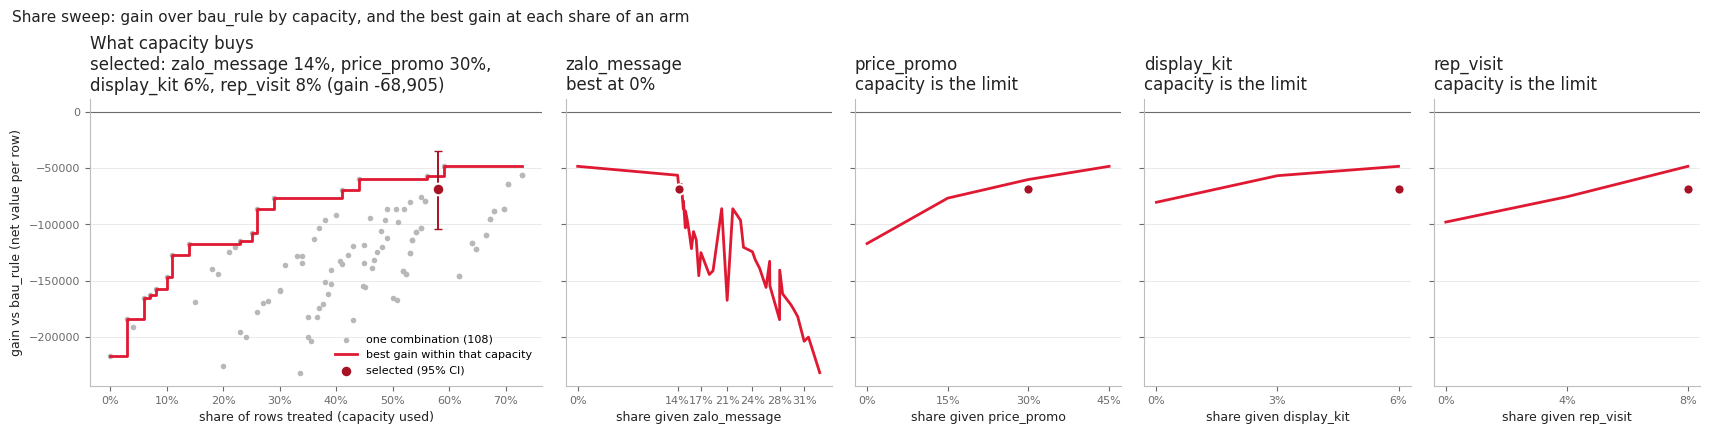

In [21]:
fig = ev_oof.plot_sweep(sweep, arm_labels=LABELS)
h.money_labels(fig)                                   # whole VND in the titles (the library prints 4 decimals)
h.wrap_titles(fig)                                    # wrap the long "selected: ..." subtitle to its panel width
X.fig(fig, "sweep",
      "Share sweep: DR gain over the BAU rule (VND per outlet-month) of every share combination; the selected one is marked.",
      "Part 7, MultiArmEvaluator.plot_sweep()")

In [22]:
# Fill order of the capacity policy: rep visits first, then display kits, an analyst's choice made with the truth of
# Part 2 in view. Check it without the truth: the reverse order on the training outlets, out of fold, caps scaled to them.
tf_cap = model.training_frame(METHOD)
assert (tf_cap["outlet_id"].to_numpy() == df_tr["outlet_id"].to_numpy()).all()
tf_cap = tf_cap.assign(region=df_tr["region"].to_numpy(), month=df_tr["month"].to_numpy())
cap_tr = h.capacity_for(df_tr, df, meta)
order_arms = {}
for name, order in {"rep first": (4, 3), "display first": (3, 4)}.items():
    caps = {k: cap_tr[k] for k in order}
    caps.update({2: len(tf_cap), 1: len(tf_cap)})
    pol = aum.MultiArmPolicy(value_per_outcome=VALUE, cost=COST, propensity_floor=h.PROPENSITY_FLOOR, strategy="capacity",
                             min_gain=0.0, capacity=caps, capacity_by="region", period="M", date_col="month")
    order_arms[name] = pol.decide(tf_cap)["best_arm"].to_numpy()
d, lo, hi = ev_oof.paired_difference(order_arms["rep first"], order_arms["display first"])
X.num(fill_order_oof={"est_difference": round(d), "ci_low": round(lo), "ci_high": round(hi),
                      "share_rows_changed": float((order_arms["rep first"] != order_arms["display first"]).mean())})
print(f"rep first minus display first (training outlets, out of fold): {d:,.0f} VND per outlet-month, 95% CI {lo:,.0f} to {hi:,.0f}; "
      f"rows with a different arm: {(order_arms['rep first'] != order_arms['display first']).mean():.1%}")

rep first minus display first (training outlets, out of fold): -11,526 VND per outlet-month, 95% CI -26,138 to 2,271; rows with a different arm: 5.8%


**Takeaway.** Without caps the model gives rep visits to 42% and display kits to 21% of test rows. The caps cut them to 8% and 6%, and the freed rows mostly get a price promo (79%), because the model predicts the promo pays almost everywhere. Modern trade never gets a display kit or a rep visit (propensity floor). Every share combination of the sweep is worth less than BAU on the training outlets, because BAU breaks the caps. The selected combination (rank 8) gives zalo to 14%, promo to 30%, display kits to 6% and rep visits to 8% of rows and leaves 42% on control (training outlets; on the test outlets the shares given differ, Part 8): of the 108 combinations swept, it is the one that treats the fewest rows among those tied with rank 1. The fill order (rep visits first) was chosen with the truth in view; on the training outlets, out of fold, rep first minus display first is -11,526 VND (CI -26,138 to 2,271), with 5.8% of rows getting a different arm: not significant, the point estimate slightly favours display kits first, so the order is not shown to matter. The duplicate rows come from zalo shares of 20% and 40%, which both end at 14% because zalo is only given where its net value is positive.

## Part 8. Policy value on the test outlets

**Purpose.** Measure what each policy is worth on outlets the model never saw.

**How.** A separate DR learner (the *referee*) is cross-fitted on the test rows only. Only its
out-of-fold outcome and propensity models are used (not its effects); they give a DR score per row and arm,
`gamma_k = mu_k + 1[arm = k] (y - mu_k) / max(e_k, 0.01)` (0.01 is the propensity clip). The value of a policy is the mean over
rows of `60,000 x gamma[row, chosen arm] - cost[chosen arm]`; `est_gain` subtracts the same
mean for all-control, so it is `mean(60,000 x (gamma[row, chosen] - gamma[row, control]) - cost[chosen])`.
This referee is not the tuner's referee of Part 5 (a T-learner on the validation outlets). The decisions come from the
model trained on the training outlets. Confidence intervals resample whole outlets (500 times).

**What to look at.** `est_gain` is the estimated net gain over giving every outlet
`control`, in VND per outlet-month, with its 95% CI. `true_gain` is the same quantity from the
true effects. `monthly_total_mVND` scales the estimate to the 20,000 outlets
(million VND per month). `gap_to_oracle` is a true-value gap: true value of the oracle (true best arm
for every row) minus the policy's true value.

The BAU rule gives display kits and rep visits to more outlets than the caps allow, so it
is not a fair baseline for the capacity policy. `bau_within_limits` is the BAU rule cut down
to the same caps: where the rule exceeds a cap in a region-month, a random subset of rows
keeps the arm and the rest get `control`. Compare `model_capacity` (and `model_top_share`) with
`bau_within_limits`, and `model_best` with `bau_rule`.

**The promo rule** (`model_capacity_promo_rule`: no price promo where `brand_share_est` is above 0.6) is
illustrative, not a tested design: the cutoff 0.6 was set with both the observed test bands of Part 11 and the
truth of Part 2 in view. Part 11 checks it on the training outlets, without the truth.

In [23]:
referee = aum.MultiArmDRLearner(n_folds=h.N_FOLDS, random_state=1, verbosity=0, group_col="outlet_id",
                                nuisance_features=["month_index"], base_model_params=h.REFEREE_PARAMS).fit(ds_te)
ref = referee.training_frame()
assert (ref["outlet_id"].to_numpy() == frame_te["outlet_id"].to_numpy()).all()
eval_frame = ref.assign(**{f"tau_{k}": frame_te[f"tau_{k}"].to_numpy() for k in range(1, 5)})  # model effects, referee scores
ev = aum.MultiArmEvaluator(eval_frame, cost=COST, value_per_outcome=VALUE, n_boot=500,
                           propensity_clip=h.PROPENSITY_CLIP, group_col="outlet_id")
net_te = h.true_net(truth_te)
n = len(df_te)
arms_top = top_share.decide(frame_te)["best_arm"].to_numpy()
specs = {"all_control": np.zeros(n, int)}
specs.update({f"{LABELS[k]}_for_all": np.full(n, k) for k in range(1, 5)})
arms_bau_cap = h.bau_within_caps(df_te, cap_test)   # BAU cut to the caps at random: the fair baseline for model_capacity
guard = (df_te["brand_share_est"] > 0.6).to_numpy()  # promo rule: no price_promo above a brand share of 0.6 (missing share: no rule); see the note above
frame_guard = frame_te.assign(tau_2=np.where(guard, -10.0, frame_te["tau_2"].to_numpy()))   # promo never pays there
arms_cap_guard = capacity.decide(frame_guard)["best_arm"].to_numpy()
specs.update({"bau_rule": df_te.rule_arm.to_numpy(), "bau_within_limits": arms_bau_cap,
              "model_best": arms_best, "model_capacity": arms_cap, "model_capacity_promo_rule": arms_cap_guard,
              "model_top_share": arms_top, "oracle (true best arm)": truth_te.true_best_arm.to_numpy()})
pt = h.policy_table(ev, specs, net_te, n_outlets_total=meta["n_outlets"])
X.num(policy_table=pt.set_index("policy").to_dict(orient="index"))
X.table(pt, "policy_table", "Net gain over all-control on the test outlets, VND per outlet-month: DR estimate with 95% CI, "
        "true value, gap to the oracle, estimate scaled to 20,000 outlets (million VND per month), and the arm mix (%).",
        "Part 8, h.policy_table on the referee's DR scores")

,policy,est_gain,ci_low,ci_high,true_gain,gap_to_oracle,monthly_total_mVND,%_control,%_zalo,%_promo,%_display,%_rep
0,all_control,0,0,0,0,321464,0,100.0000,0.0000,0.0000,0.0000,0.0000
1,zalo_message_for_all,-24665,-111675,79225,24566,296898,-493,0.0000,100.0000,0.0000,0.0000,0.0000
2,price_promo_for_all,60911,-20634,152000,93660,227803,1218,0.0000,0.0000,100.0000,0.0000,0.0000
3,display_kit_for_all,-833237,-925971,-743087,-148407,469871,-16665,0.0000,0.0000,0.0000,100.0000,0.0000
4,rep_visit_for_all,-391075,-488551,-311489,196441,125023,-7821,0.0000,0.0000,0.0000,0.0000,100.0000
5,bau_rule,161660,104966,220986,199693,121770,3233,49.2000,2.9000,22.4000,11.7000,13.8000
6,bau_within_limits,120091,73330,167386,119775,201689,2402,60.7000,2.9000,22.4000,6.0000,8.1000
7,model_best,215881,139364,294823,278349,43115,4318,3.2000,1.8000,32.7000,20.5000,41.7000
8,model_capacity,105856,26735,185820,168203,153260,2117,4.8000,1.7000,79.4000,6.0000,8.1000
9,model_capacity_promo_rule,126162,48177,200897,178762,142701,2523,17.4000,8.0000,60.5000,6.0000,8.1000


In [24]:
pairs = {"model_best - bau_rule": (arms_best, specs["bau_rule"]),
         "model_capacity - bau_rule": (arms_cap, specs["bau_rule"]),
         "model_capacity - bau_within_limits": (arms_cap, arms_bau_cap),
         "model_capacity_promo_rule - bau_within_limits": (arms_cap_guard, arms_bau_cap),
         "model_capacity_promo_rule - model_capacity": (arms_cap_guard, arms_cap),
         "model_best - model_capacity": (arms_best, arms_cap),
         "model_top_share - bau_rule": (arms_top, specs["bau_rule"]),
         "model_top_share - bau_within_limits": (arms_top, arms_bau_cap)}
rows = []
for name, (a, b) in pairs.items():
    d, lo, hi = ev.paired_difference(a, b)
    rows.append({"comparison": name, "est_difference": round(d), "ci_low": round(lo), "ci_high": round(hi),
                 "true_difference": round(h.true_value(net_te, a) - h.true_value(net_te, b))})
pdiff = pd.DataFrame(rows)
X.num(paired=pdiff.set_index("comparison").to_dict(orient="index"))
X.table(pdiff, "paired_differences", "Paired differences between policies on the test outlets (VND per outlet-month): "
        "DR estimate with 95% CI (same rows, outlets resampled) and the true difference.", "Part 8, MultiArmEvaluator.paired_difference()")

,comparison,est_difference,ci_low,ci_high,true_difference
0,model_best - bau_rule,54221,-1125,110126,78655
1,model_capacity - bau_rule,-55804,-119536,13618,-31490
2,model_capacity - bau_within_limits,-14235,-83586,57084,48428
3,model_capacity_promo_rule - bau_within_limits,6070,-63936,72631,58987
4,model_capacity_promo_rule - model_capacity,20305,-6830,45217,10559
5,model_best - model_capacity,110025,61496,157170,110146
6,model_top_share - bau_rule,-27160,-86265,40741,-31033
7,model_top_share - bau_within_limits,14410,-45426,82397,48886


**How large a pilot?** The comparison that matters for a decision under the caps
(`model_capacity - bau_within_limits`) is not settled by these 6,000 outlets. A pilot would
split outlets at random into two sides. The cell below computes, from observed outcomes only
(no truth), the smallest difference such a pilot detects with 80% power at the 5% level:
9,000 outlets per side (20,000 outlets minus a 10% random holdout, split in two), over 3 or
6 months, with a raw comparison of side means or one adjusted for features known before the
pilot (`vol_avg_3m`, `order_frequency_3m`, `n_coolers`, `channel`). Columns: `sd_per_outlet` is the
standard deviation over outlets of an outlet's mean monthly gross margin in the pilot window (residual SD for
the adjusted analysis; arm costs are fixed per arm and add no noise),
`se_difference` the standard error of the difference of the two side means, `mde_80_power` = 2.8 x
`se_difference`, `r2_adjustment` the share of variance explained by the pre-pilot features.

In [25]:
pw = h.pilot_power(df, VALUE, outlets_per_side=9_000, months=(3, 6))
X.num(pilot_power=pw.to_dict(orient="records"))
X.table(pw, "pilot_power", "Pilot size: minimum detectable difference (VND per outlet-month, 80% power, 5% two-sided) of a "
        "randomised pilot with 9,000 outlets per side, by duration and analysis.", "Part 8, h.pilot_power")

,months,analysis,outlets_per_side,sd_per_outlet,se_difference,mde_80_power,r2_adjustment
0,3,raw,9000,3749462,55894,156502,NaN
1,3,adjusted,9000,1793870,26741,74876,0.7710
2,6,raw,9000,3623678,54019,151252,NaN
3,6,adjusted,9000,1678658,25024,70067,0.7850


In [26]:
agr = h.agreement_by(df_te, arms_best, truth_te.true_best_arm.to_numpy())
agr_bau = h.agreement_by(df_te, specs["bau_rule"], truth_te.true_best_arm.to_numpy())
agr["bau_agreement_%"] = agr_bau["agreement_%"].to_numpy()
X.num(agreement=agr.set_index("channel")["agreement_%"].to_dict(), agreement_bau=agr.set_index("channel")["bau_agreement_%"].to_dict())
X.table(agr, "agreement", "Share of test rows (%) where the model's best-arm policy and the BAU rule choose the true best arm, by channel.",
        "Part 8, h.agreement_by")

,channel,rows,agreement_%,bau_agreement_%
0,modern_trade,3480,52.4000,30.1000
1,off_trade_grocery,11388,65.3000,32.1000
2,off_trade_minimart,6486,72.4000,35.6000
3,on_trade_bar,6864,76.6000,32.3000
4,on_trade_restaurant,7782,71.8000,36.1000
5,all rows,36000,68.9000,33.4000


**Takeaway.** Without caps the model gains 54,221 VND per outlet-month over BAU, but the CI (-1,125 to 110,126) includes zero, so the test outlets alone do not prove it (true 78,655). It picks the true best arm for 68.9% of rows against 33.4% for BAU. model_capacity and model_top_share are estimated below the uncapped BAU (capacity -55,804, top_share -27,160, both CIs include zero; true -31,490 and -31,033), which only says BAU uses more display kits and rep visits than the caps allow. Against its fair baseline, BAU within the caps, model_top_share is at 14,410 VND (CI -45,426 to 82,397; true 48,886). Against BAU cut to the caps, the truth says the capacity model is 48,428 VND better, but the estimate (-14,235, CI -83,586 to 57,084) cannot tell them apart. The caps cost 110,025 VND (CI 61,496 to 157,170; true 110,146). The capacity policy with no promo above brand share 0.6 is worth 126,162 VND (true 178,762): 20,305 more than without the rule (CI -6,830 to 45,217; true 10,559), and 6,070 against BAU cut to the caps (CI -63,936 to 72,631; true 58,987). The rule helps in truth, but neither estimate is significant. A randomised pilot with 9,000 outlets per side detects (80% power) about 74,876 VND in 3 months and 70,067 in 6 months with the adjusted analysis (156,502 and 151,252 without adjustment). Estimates for display_kit_for_all and rep_visit_for_all are far off because those policies use the arms in modern trade, where they were never given.

## Part 9. Uplift curve and Qini per arm

**Purpose.** Check that the model ranks rows well, arm by arm, independent of the policy.

**How to read.** For one arm, rows are sorted by the model's predicted effect of that arm,
highest first. The curve shows the DR net gain (VND per outlet-month, averaged over all rows)
of giving the arm to the top x% and control to the rest. A curve above the straight line from
0 to "everyone gets the arm" means the ranking beats random targeting; the Qini is the area
between the two (with a 95% CI). The peak shows the share of rows worth treating with that arm alone.

In [27]:
# the same on rows where every arm has evidence (referee propensity >= the floor for all arms): modern trade
# never got display kits or rep visits, and its extrapolated effects sit at the bottom of those rankings
has_ev = (eval_frame[[f"e_{k}" for k in range(5)]] >= h.PROPENSITY_FLOOR).all(axis=1).to_numpy()
ev_e = aum.MultiArmEvaluator(eval_frame[has_ev].reset_index(drop=True), cost=COST, value_per_outcome=VALUE, n_boot=500,
                             propensity_clip=h.PROPENSITY_CLIP, group_col="outlet_id")
qini_e = ev_e.qini_by_arm()
X.num(qini_evidence=qini_e.to_dict(orient="records"), qini_evidence_rows=int(has_ev.sum()))
print(f"rows with evidence for every arm by the referee's propensities: {int(has_ev.sum()):,} of {len(has_ev):,} "
      "(Part 11 and the training side of Part 10 use the trained model's propensities, so their counts differ slightly)")
X.table(qini_e, "qini_evidence", "Per arm on the test rows where every arm has evidence: gain if all get it, auuc, "
        "Qini with 95% CI, and whether the ranking beats random.", "Part 9, MultiArmEvaluator.qini_by_arm() on rows with evidence")

rows with evidence for every arm by the referee's propensities: 32,605 of 36,000 (Part 11 and the training side of Part 10 use the trained model's propensities, so their counts differ slightly)


,arm,ate,auuc,qini,qini_ci_low,qini_ci_high,ranks_better_than_random
0,1,"-77,265.5018","-34,409.2705","4,223.4804","-26,505.6798","34,014.8956",False
1,2,"40,731.7108","47,132.2248","26,766.3694","-2,682.2366","52,648.8152",False
2,3,"-236,490.0545","-32,708.5048","85,536.5225","61,900.5950","110,383.4588",True
3,4,"135,847.3353","106,444.2700","38,520.6024","20,433.6235","61,450.3403",True


In [28]:
qini = ev.qini_by_arm()
X.num(qini=qini.to_dict(orient="records"))
X.table(qini, "qini", "Per arm on the test outlets: gain of giving the arm to everyone (ate), area under the gain curve (auuc), "
        "Qini with 95% CI, and whether the ranking beats random targeting.", "Part 9, MultiArmEvaluator.qini_by_arm()")

,arm,ate,auuc,qini,qini_ci_low,qini_ci_high,ranks_better_than_random
0,1,"-24,664.9235","-16,740.5135","-4,408.0517","-44,392.1281","32,309.3939",False
1,2,"60,911.0504","71,068.1303","40,612.6051","6,421.1726","75,806.0023",True
2,3,"-833,237.4902","-65,224.4039","351,394.3412","311,165.3344","388,830.8198",True
3,4,"-391,074.8291","83,244.3639","278,781.7784","245,051.8981","313,921.4291",True


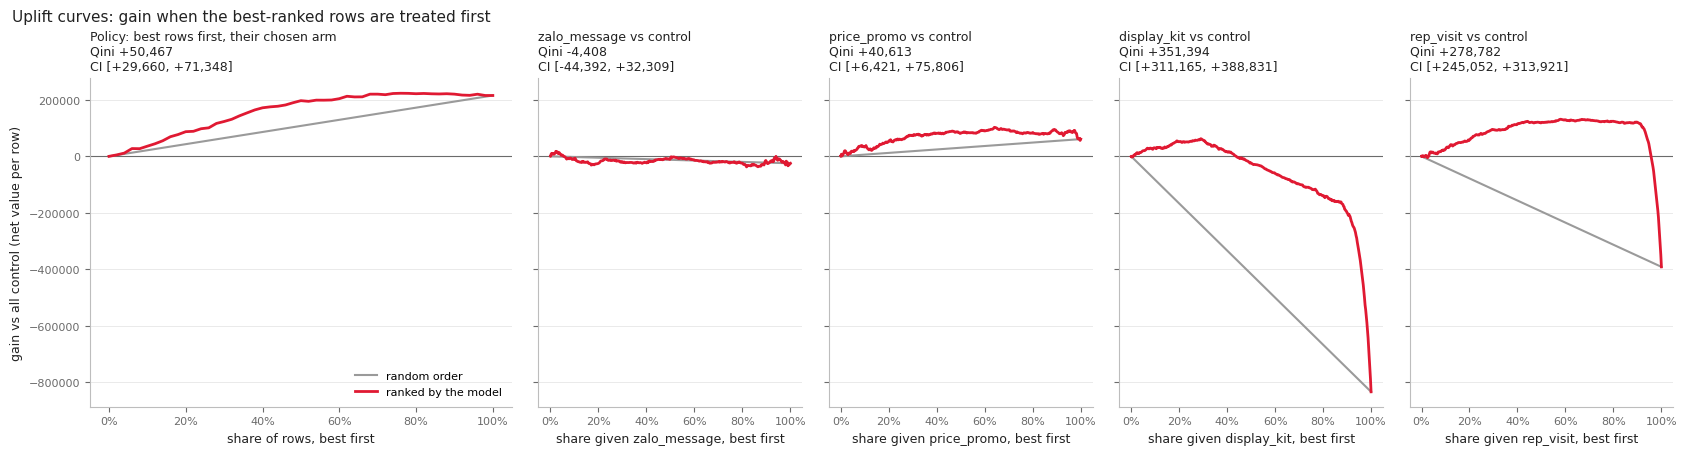

In [29]:
fig = ev.plot_uplift_curve(best, arm_labels=LABELS, figsize=(17, 4.6))
for ax in fig.axes:                                   # shorter panel titles: whole VND, CI on its own line
    head, _, q = ax.get_title(loc="left").partition("\nQini ")
    if q:
        v = [round(float(t)) for t in q.replace("[", "").replace("]", "").replace(",", " ").split()]
        ax.set_title(f"{head}\nQini {v[0]:+,}\nCI [{v[1]:+,}, {v[2]:+,}]", fontsize=9, loc="left")
X.fig(fig, "uplift_curve",
      "Uplift (gain) curves on the test outlets: DR net gain in VND per outlet-month when the top x% of rows "
      "by predicted effect get the arm.", "Part 9, MultiArmEvaluator.plot_uplift_curve()")

**Takeaway.** On all test rows the rankings beat random targeting for price_promo, display_kit and rep_visit, not for zalo_message (true effect about half a case everywhere). These Qini values include modern trade, where the display and rep effects are extrapolated; on the 32,605 rows with evidence for every arm (last table), only display_kit and rep_visit rank better than random; for zalo_message and price_promo the Qini interval includes zero (price_promo: 26,766, CI -2,682 to 52,649). Display kits pay only for the rows the model ranks first. The fall at the end of the rep visit curve comes from modern-trade rows, which the policy never treats; on rows with evidence, the estimated gain of a rep visit for everyone is positive (no interval is computed for it).

## Part 10. Calibration

**Purpose.** The best-arm policy compares effect sizes across arms in VND, so the size of each
predicted effect matters, not only its ranking. Calibration checks whether rows predicted to gain
2 cases really gain about 2 cases.

**How.** Rows are binned by predicted effect; in each bin the mean predicted effect is compared
with the DR observed effect. The slope of observed on predicted is 1 for a well-calibrated arm;
below 1 means predictions are spread wider than the data supports. An isotonic calibrator fitted
on the training outlets (out of fold) can rescale the effects while keeping their order.

**Which rows.** Only rows where every arm has evidence (estimated propensity of at least 0.02 for
all five arms). Modern trade never got `display_kit` or `rep_visit`, so the model's effects for those
arms there are extrapolations; the policy never uses them (propensity floor), and including them
would make the slopes look perfect for the wrong reason.

**What to look at.** The slopes, the error before and after calibration on the test outlets, and
whether calibrating changes the decisions or their value.

In [30]:
# Calibrate on rows where every arm has evidence (estimated propensity >= the floor for all arms).
# Modern trade never got display_kit or rep_visit: its predicted effects for those arms are
# extrapolations the policy never uses, and they would dominate the fit and the slopes.
def with_evidence(f):
    return f[(f[[f"e_{k}" for k in range(5)]] >= h.PROPENSITY_FLOOR).all(axis=1)].reset_index(drop=True)
oof = model.training_frame(METHOD)
X.num(evidence_share_train=len(with_evidence(oof)) / len(oof), evidence_share_test=len(with_evidence(eval_frame)) / len(eval_frame))
cal = aum.MultiArmCalibrator(method="isotonic").fit(with_evidence(oof))
ce = cal.calibration_error(with_evidence(eval_frame))
print(f"rows with evidence for every arm: training {len(with_evidence(oof)) / len(oof):.1%}, test {len(with_evidence(eval_frame)) / len(eval_frame):.1%}")
X.table(cal.slope_, "calibration_slope", "Calibration slope per arm (training outlets, out of fold, rows with evidence for every arm): DR observed effect regressed on predicted effect.",
        "Part 10, MultiArmCalibrator.slope_")

rows with evidence for every arm: training 89.7%, test 90.6%


,arm,mean_effect,slope,slope_se,slope_ci_low,slope_ci_high,mae_raw,mae_calibrated,heterogeneity_detected
0,1,0.6182,-0.0051,0.1552,-0.3092,0.2991,1.9935,0.9730,False
1,2,3.2450,-0.1901,0.2011,-0.5842,0.2040,1.6648,1.1616,False
2,3,4.8311,0.5340,0.0355,0.4645,0.6036,2.2953,0.7246,True
3,4,6.3509,0.1484,0.0349,0.0800,0.2168,2.8812,0.8565,True


*Columns.* `mean_effect`: mean DR observed effect on these rows (cases); `slope`: coefficient of the DR
observed effect regressed on the predicted effect (1 = differences between rows are right, below 1 = too
wide, near 0 = not found); `heterogeneity_detected`: the slope's 95% CI lies above 0.

In [31]:
X.table(ce, "calibration_error", "Calibration on the test outlets (rows with evidence for every arm): mean absolute error between predicted and DR observed effect per bin (cases), before and after calibration.", "Part 10, MultiArmCalibrator.calibration_error()")

,arm,mae_raw,mae_calibrated,n_bins
0,1,1.8908,2.3535,10
1,2,1.8164,1.8524,10
2,3,2.2206,2.1506,10
3,4,2.5802,1.8185,10


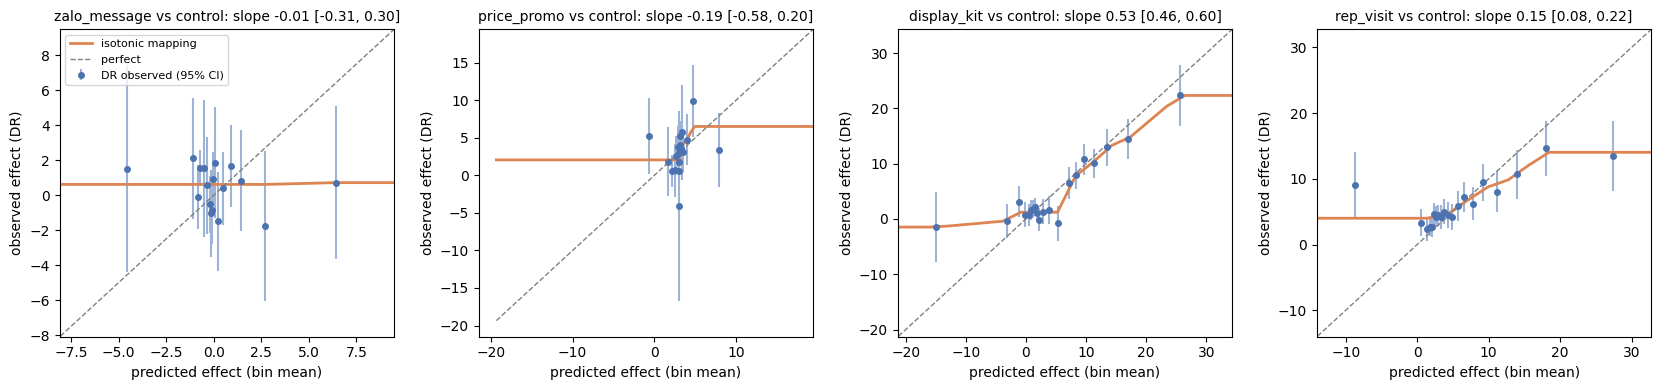

In [32]:
fig = cal.plot_calibration(arm_labels=LABELS)
h.zoom_to_points(fig)                                 # zoom on the binned points: the calibrator's line extends to the most extreme predictions
X.fig(fig, "calibration",
      "Calibration per arm (training outlets, out of fold, rows with evidence for every arm): mean predicted effect (x, cases) against DR observed effect (y, cases) per bin; "
      "the diagonal is perfect calibration.", "Part 10, MultiArmCalibrator.plot_calibration()")

In [33]:
arms_cal = best.decide(cal.transform(frame_te))["best_arm"].to_numpy()
d, lo, hi = ev.paired_difference(arms_cal, arms_best)
X.num(calibration_changed_share=(arms_cal != arms_best).mean(), calibration_gain=[d, lo, hi],
      calibration_true_gain=h.true_value(net_te, arms_cal) - h.true_value(net_te, arms_best))
print(f"decisions changed by calibration: {(arms_cal != arms_best).mean():.1%} of test rows; "
      f"value change {d:,.0f} VND [{lo:,.0f}, {hi:,.0f}]; true change {h.true_value(net_te, arms_cal) - h.true_value(net_te, arms_best):,.0f} VND")

decisions changed by calibration: 29.2% of test rows; value change -10,722 VND [-60,830, 44,665]; true change -3,168 VND


**Takeaway.** On rows with evidence for every arm, the data confirms differences between rows for display kits and rep visits (slopes 0.53 and 0.15: the predicted differences are too wide), and not for messages and promos. For the promo, the slope alone cannot tell failure from noise; the truth (synthetic data only) shows a model failure: the true promo effect varies strongly with brand share (Part 2), and the model misses most of it. The isotonic calibrator lowers the binned error for display kits and rep visits but raises it for messages (1.89 to 2.35 cases) and slightly for promos (1.82 to 1.85). The mae columns of the slope table are in sample for the calibrator (fitted on those rows), so they look better than they are. The calibrator changes 29% of decisions with no detectable gain in value (-10,722 VND, CI -60,830 to 44,665; true -3,168), so it is not applied (a decision made on the test outlets).

## Part 11. What drives the effects and the decisions

**Purpose.** Explain the model in the order a reader needs: which features matter (importance,
checked against a noise floor), which features change the chosen arm (decision importance),
how the main drivers move the effect per channel, and why one outlet gets its arm.

**Terms.** *Feature importance*: how much each feature moves the predicted effect of an arm.
*Noise floor*: the importance reached by shuffled copies of real features (pure noise); a feature
below it is not a reliable driver. *Decision importance*: share of rows whose chosen arm changes
when one feature is shuffled.

**Which rows.** A sample of 20,000 test rows among those where every arm has evidence (estimated
propensity of at least 0.02 for all five arms). This leaves out modern trade, which never got
`display_kit` or `rep_visit`: the model's effects for those two arms there are extrapolations, not
estimates, and would dominate every importance number. Modern trade decisions are covered in Parts 7, 8 and 13.

In [34]:
# Explain the model where it has evidence: test rows with an estimated propensity >= 0.02 for every arm.
ev_mask = (frame_te[[f"e_{k}" for k in range(5)]] >= h.PROPENSITY_FLOOR).all(axis=1).to_numpy()
ds_ev = tuner.best_filter_.transform(h.make_dataset(df_te[ev_mask], meta, FEATURES))
X.num(interpret_rows=int(ev_mask.sum()), interpret_channels_left_out=sorted(set(df_te.channel[~ev_mask])))
print(f"rows explained: {ev_mask.sum():,} of {len(ev_mask):,}; left out by channel:", df_te.channel[~ev_mask].value_counts().to_dict())
it = aum.MultiArmInterpreter(model, ds_ev, method=METHOD, n_sample=20_000, arm_labels=LABELS)
nf = it.importance_noise_floor(ds_tr)
# floor per comparison = largest importance of the 5 shadow (shuffled copy) features; ratio_to_floor = the
# feature's largest importance / floor over the comparisons; above_floor = ratio >= 1.5 (the margin) for at least one
print("noise floor per comparison:", nf.attrs["noise_floor"], "| margin:", nf.attrs["margin"])
X.table(nf.reset_index().rename(columns={"index": "feature"}), "noise_floor",
        "Feature importance per arm (vs control) with the noise floor from 5 shadow features; above_floor marks real drivers.",
        "Part 11, MultiArmInterpreter.importance_noise_floor()")

rows explained: 32,520 of 36,000; left out by channel: {'modern_trade': 3480}


noise floor per comparison: {'zalo_message vs control': 0.0969, 'price_promo vs control': 0.0206, 'display_kit vs control': 0.245, 'rep_visit vs control': 0.2496} | margin: 1.5


,feature,zalo_message vs control,price_promo vs control,display_kit vs control,rep_visit vs control,overall,ratio_to_floor,n_arms_above,drives,above_floor
0,order_frequency_3m,0.1272,0.1258,3.6774,3.1523,7.0828,15.0070,3,"price_promo vs control, display_kit vs control, rep_visit vs control",True
1,vol_avg_3m,0.3491,0.1325,3.1098,2.7470,6.3384,12.6905,4,"zalo_message vs control, price_promo vs control, display_kit vs control, rep_visit vs control",True
2,channel,0.1373,0.0395,3.3313,2.7924,6.3005,13.5946,3,"price_promo vs control, display_kit vs control, rep_visit vs control",True
3,n_coolers,0.1508,0.0440,3.3077,0.2673,3.7698,13.4985,3,"zalo_message vs control, price_promo vs control, display_kit vs control",True
4,vol_last_1m,0.1727,0.1620,1.2052,1.0422,2.5821,7.8472,4,"zalo_message vs control, price_promo vs control, display_kit vs control, rep_visit vs control",True
5,vol_trend_3m,0.0285,0.0000,0.3501,1.9723,2.3509,7.9029,1,rep_visit vs control,True
6,seating_capacity,0.2484,0.1201,0.6160,1.1424,2.1269,5.8178,4,"zalo_message vs control, price_promo vs control, display_kit vs control, rep_visit vs control",True
7,outlet_size,0.2239,0.0635,0.3879,0.7181,1.3934,3.0748,4,"zalo_message vs control, price_promo vs control, display_kit vs control, rep_visit vs control",True
8,tet_month,0.0506,0.0782,0.5238,0.3954,1.0481,3.7897,3,"price_promo vs control, display_kit vs control, rep_visit vs control",True
9,brand_share_est,0.0771,0.2416,0.3915,0.3366,1.0468,11.7033,2,"price_promo vs control, display_kit vs control",True


Columns of the next table: `share_switched` share of rows whose best arm changes; `value_drop` net value
lost (VND per outlet-month) when deciding with the shuffled feature, valued with the model's own effects;
`value_drop_dr` with CI, the same loss valued with the DR observed outcomes (`dr_significant`: CI above 0);
`effect_shift` mean absolute change of the predicted effects (cases); `rank` the library's order by
`value_drop`. Noise floor table above: `overall` is the sum of the importances over the four comparisons,
`n_arms_above` the number of comparisons where the feature clears 1.5 x the floor. The tests are per feature
and arm, at 5%, without adjustment for the number of tests.

In [35]:
di = it.decision_importance(best).sort_values("share_switched", ascending=False).reset_index(drop=True)
X.table(di, "decision_importance", "Decision importance: share of rows whose best arm changes when the feature is shuffled.",
        "Part 11, MultiArmInterpreter.decision_importance()")

,feature,share_switched,value_drop,value_drop_dr,value_drop_dr_ci_low,value_drop_dr_ci_high,dr_significant,effect_shift,rank
0,n_coolers,0.2521,"71,698.4644","55,113.4906","16,597.9661","93,629.0151",True,1.1296,1
1,channel,0.2334,"46,856.0445","70,945.5176","39,299.9325","102,591.1026",True,0.9078,2
2,vol_trend_3m,0.2125,"27,878.9021","38,262.0667","7,199.7587","69,324.3748",True,0.8198,3
3,vol_avg_3m,0.1444,"17,231.3779","19,058.1950","-13,344.4567","51,460.8467",False,1.2487,5
4,seating_capacity,0.1108,"13,435.7601","9,744.6575","-10,840.8107","30,330.1257",False,0.7956,6
5,vol_last_1m,0.1050,"17,268.7868","11,619.5229","-25,625.9547","48,865.0005",False,1.0008,4
6,outlet_size,0.0832,"5,579.7250","-11,883.1776","-29,083.3139","5,316.9588",False,0.7266,9
7,brand_share_est,0.0832,"4,076.8217","10,800.5382","-14,736.4018","36,337.4782",False,0.4625,10
8,order_frequency_3m,0.0762,"9,490.8292","8,351.6031","-12,995.5012","29,698.7074",False,0.6260,7
9,days_since_last_order,0.0676,"3,303.3634","10,931.4815","-7,288.4161","29,151.3790",False,0.3551,11


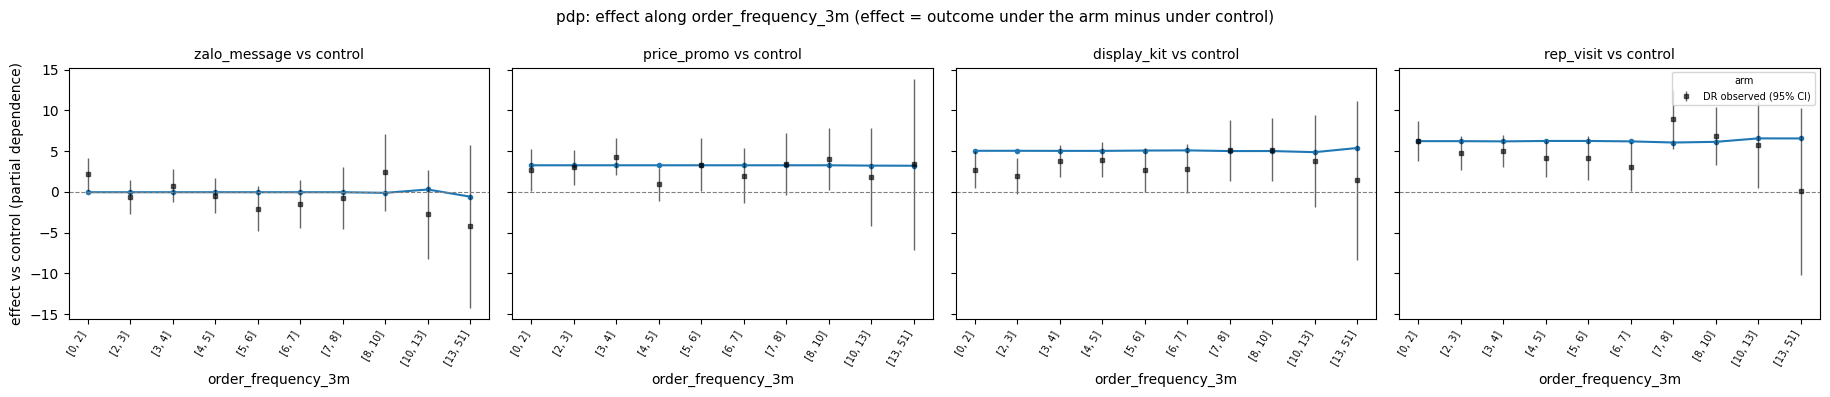

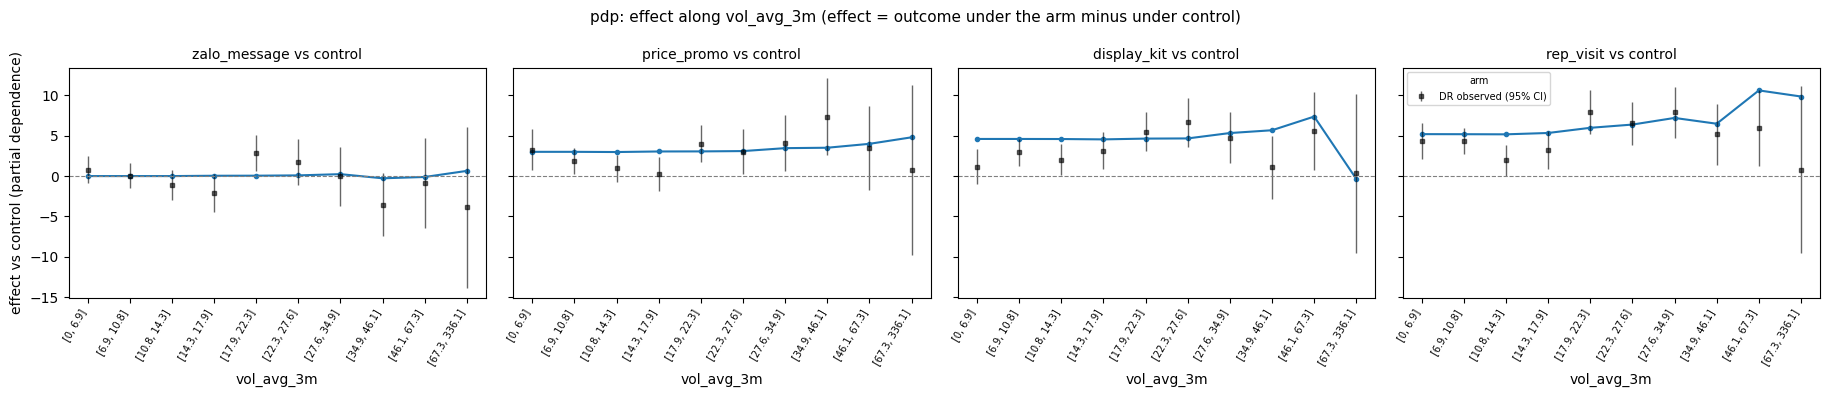

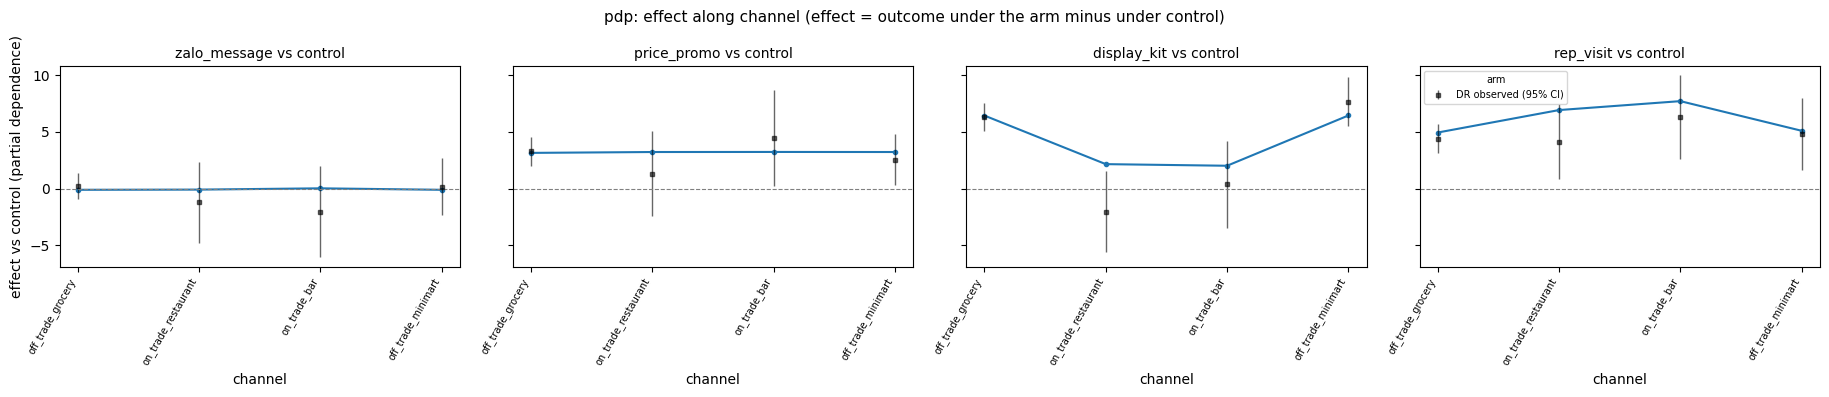

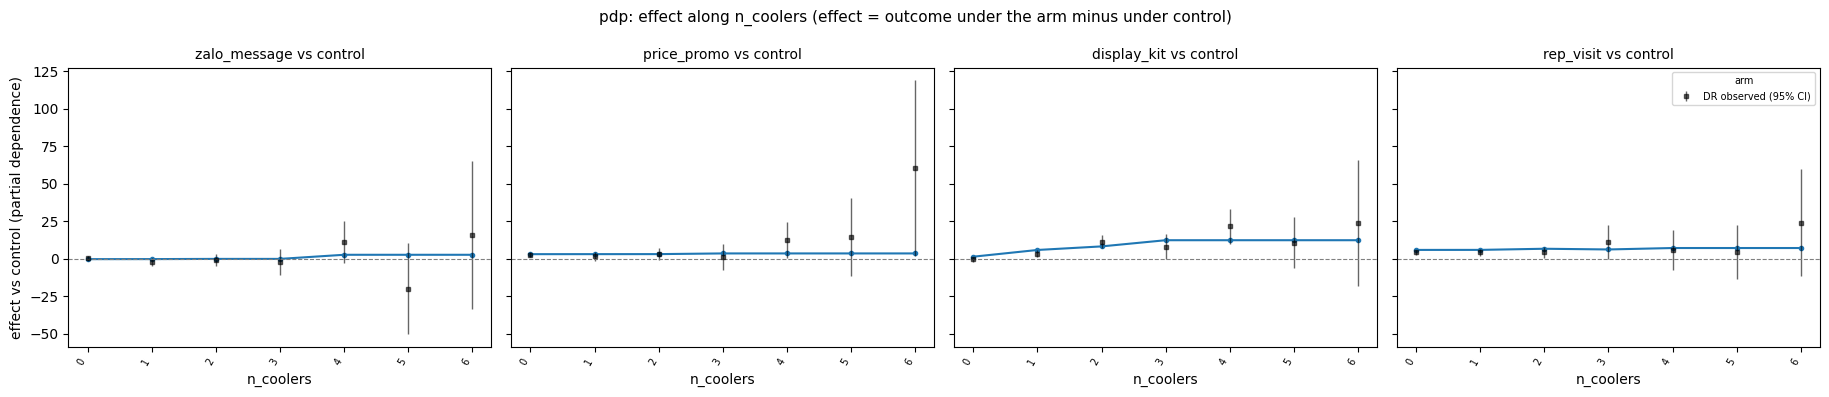

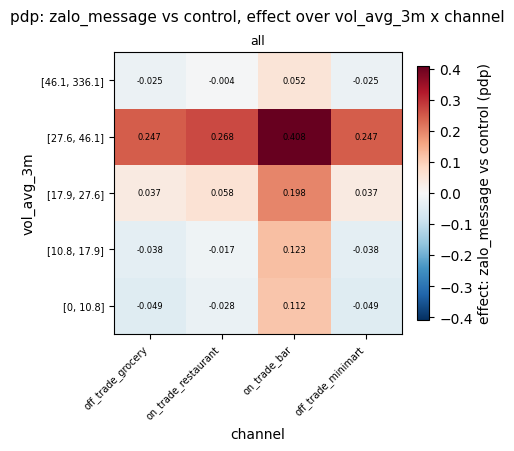

explained: ['order_frequency_3m', 'vol_avg_3m', 'channel', 'n_coolers'] | strongest interaction: {'feature_1': 'vol_avg_3m', 'feature_2': 'channel', 'arm': 1, 'comparison': 'zalo_message vs control', 'strength': 0.302, 'signal_to_noise': 6.9846}


In [36]:
et = it.explain_top(n=4, noise_floor=nf, interaction=True)
X.num(explain_top_features=et["features"],
      interaction={k: v for k, v in (et["interaction"] or {}).items() if k != "pairs"})
for k, f in et["figures"].items():
    display(X.fig(f, "explain_top_" + k.replace(" ", "_"), f"explain_top: predicted effect (cases) of each arm along {k}.",
                  "Part 11, MultiArmInterpreter.explain_top()"))
    plt.close(f)
print("explained:", et["features"], "| strongest interaction:", {k: v for k, v in (et["interaction"] or {}).items() if k != "pairs"})

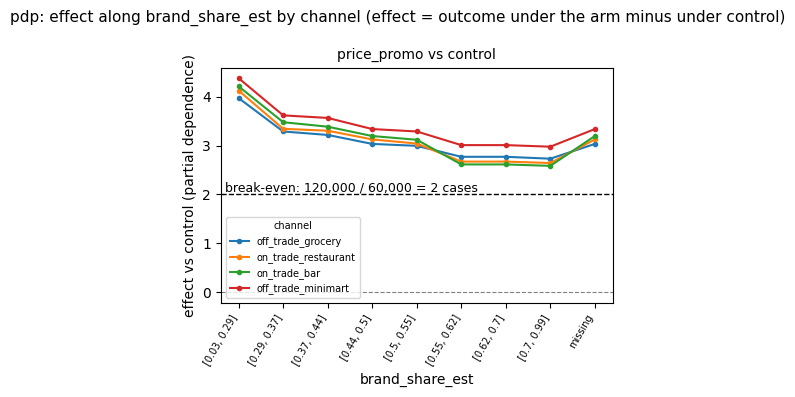

In [37]:
fig = it.plot_marginal_effect("brand_share_est", by="channel", arms=[2], bins=8)
for ax in fig.axes[:1]:
    ax.axhline(COST[2] / VALUE, color="black", ls="--", lw=1)
    ax.text(ax.get_xlim()[0], COST[2] / VALUE, " break-even: 120,000 / 60,000 = 2 cases", va="bottom", fontsize=9)
me_promo = it.marginal_effect("brand_share_est", by="channel", arms=[2], bins=8)
X.table(me_promo[["group", "bin", "effect", "n"]], "promo_vs_share_model", "Predicted price_promo effect (cases) by band of brand_share_est and channel.",
        "Part 11, MultiArmInterpreter.marginal_effect()", show=False)
X.fig(fig, "promo_vs_share", "Predicted effect of price_promo (cases per outlet-month) along brand_share_est, one line per channel. "
      "Above the dashed line (2 cases) the promo pays for its cost.", "Part 11, MultiArmInterpreter.plot_marginal_effect()")

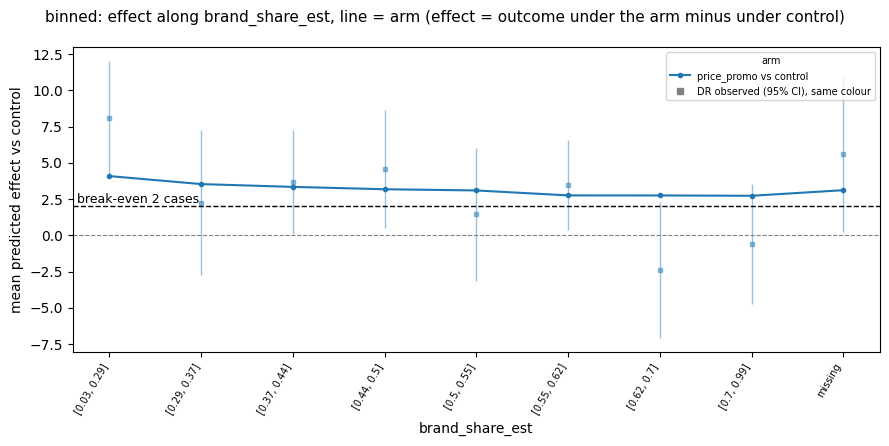

,bin,effect,actual,actual_ci_low,actual_ci_high,n
0,"[0.03, 0.29]",4.0884,8.0634,4.1115,12.0152,2462
1,"[0.29, 0.37]",3.5374,2.2464,-2.7458,7.2386,2366
2,"[0.37, 0.44]",3.3447,3.6653,0.0770,7.2537,2304
3,"[0.44, 0.5]",3.1828,4.5536,0.4830,8.6243,2429
4,"[0.5, 0.55]",3.0987,1.4734,-3.1120,6.0587,2063
5,"[0.55, 0.62]",2.7587,3.4606,0.3529,6.5682,2371
6,"[0.62, 0.7]",2.7541,-2.3799,-7.0852,2.3254,2160
7,"[0.7, 0.99]",2.7323,-0.5959,-4.7480,3.5562,2291
8,missing,3.1175,5.5999,0.2194,10.9804,1554


In [38]:
# the same feature, all channels together, with the DR observed effect per band (dots, 95% CI) next to the model's line
fig = it.plot_marginal_effect("brand_share_est", arms=[2], bins=8, kind="binned", show_actual=True, facet=None)
for ax in fig.axes[:1]:
    ax.axhline(COST[2] / VALUE, color="black", ls="--", lw=1)
    ax.text(ax.get_xlim()[0], COST[2] / VALUE, " break-even 2 cases", va="bottom", fontsize=9)
obs = it.marginal_effect("brand_share_est", arms=[2], bins=8, kind="binned")
X.table(obs[["bin", "effect", "actual", "actual_ci_low", "actual_ci_high", "n"]], "promo_vs_share_observed",
        "price_promo by band of brand_share_est: model effect and DR observed effect with 95% CI (cases per outlet-month).",
        "Part 11, MultiArmInterpreter.marginal_effect(kind='binned')")
display(X.fig(fig, "promo_vs_share_observed", "Model effect of price_promo (line) and DR observed effect with 95% CI (dots) by band of "
      "brand_share_est, cases per outlet-month. Dashed: break-even at 2 cases.", "Part 11, MultiArmInterpreter.plot_marginal_effect(show_actual=True)"))
plt.close(fig)
obs[["bin", "effect", "actual", "actual_ci_low", "actual_ci_high", "n"]]

**The promo cutoff, checked on the training outlets.** The table above uses test rows, and the policy
with the promo rule (cutoff 0.6) is valued on the same test outlets in Part 8. The cell below repeats the
observed promo effect by band of brand share on the *training* outlets, from the out-of-fold DR scores
(rows with evidence for every arm), so the cutoff can be judged on rows that did not value it. CIs resample
whole outlets.

In [39]:
tf = model.training_frame(METHOD)
gam = {k: tf[f"mu_{k}"] + (tf["arm"] == k) * (tf["y"] - tf[f"mu_{k}"]) / np.maximum(tf[f"e_{k}"], h.PROPENSITY_CLIP) for k in (0, 2)}
cut = pd.DataFrame({"outlet_id": tf["outlet_id"].to_numpy(), "dr_promo": (gam[2] - gam[0]).to_numpy(),
                    "share": ds_tr.df["brand_share_est"].to_numpy()})
cut = cut[(tf[[f"e_{k}" for k in range(5)]] >= h.PROPENSITY_FLOOR).all(axis=1).to_numpy()]
cut["band"] = pd.cut(cut["share"], [0, 0.3, 0.45, 0.6, 0.7, 1.0], include_lowest=True).astype(str).where(cut["share"].notna(), "missing")
rng = np.random.RandomState(0)
rows = []
for band, g in cut.groupby("band", sort=True):
    per = g.groupby("outlet_id")["dr_promo"].agg(["sum", "count"])
    boot = [per.iloc[i]["sum"].sum() / per.iloc[i]["count"].sum() for i in (rng.randint(0, len(per), len(per)) for _ in range(300))]
    rows.append({"band": band, "observed_effect": g["dr_promo"].mean(), "ci_low": np.percentile(boot, 2.5),
                 "ci_high": np.percentile(boot, 97.5), "n": len(g)})
cut_tab = pd.DataFrame(rows).round(4)
X.table(cut_tab, "promo_cutoff_train", "Observed price_promo effect (cases, out-of-fold DR, 95% CI over outlets) by band of "
        "brand_share_est on the training outlets, rows with evidence for every arm. Break-even: 2 cases.", "Part 11, pandas on training_frame()")

,band,observed_effect,ci_low,ci_high,n
0,"(-0.001, 0.3]",4.9781,3.2177,6.8854,10230
1,"(0.3, 0.45]",4.8503,3.4795,6.0515,18138
2,"(0.45, 0.6]",2.1034,1.1129,3.1976,21390
3,"(0.6, 0.7]",1.1512,-0.8288,3.1224,10476
4,"(0.7, 1.0]",1.9802,0.2468,3.7239,8826
5,missing,4.9433,2.6289,7.3079,6282


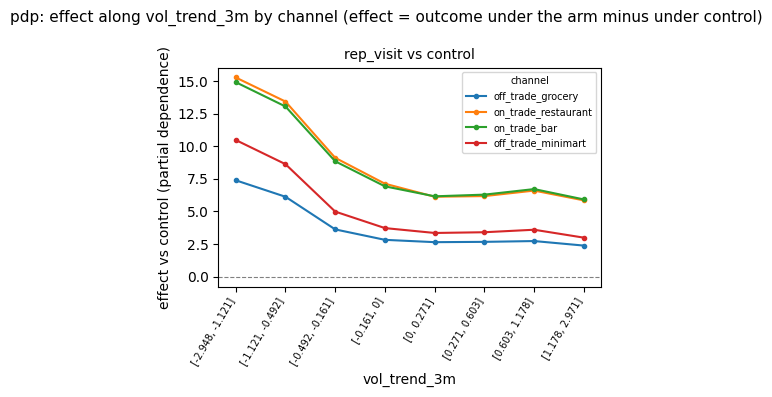

In [40]:
X.fig(it.plot_marginal_effect("vol_trend_3m", by="channel", arms=[4], bins=8), "rep_vs_trend",
      "Predicted effect of rep_visit (cases per outlet-month) along vol_trend_3m, one line per channel.",
      "Part 11, MultiArmInterpreter.plot_marginal_effect()")

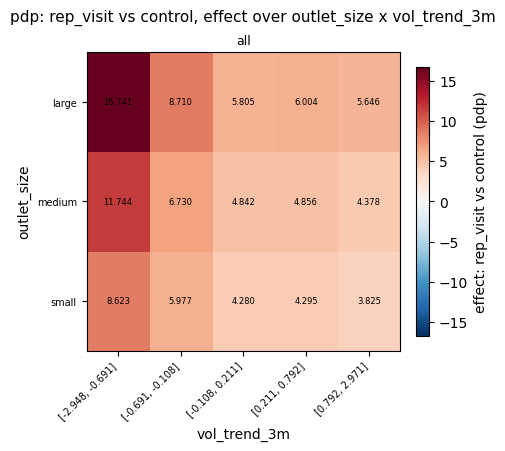

In [41]:
X.fig(it.plot_marginal_effect_2d("outlet_size", "vol_trend_3m", arm=4, bins=(3, 5)), "rep_size_trend_2d",
      "Predicted effect of rep_visit (cases) by outlet_size and vol_trend_3m.", "Part 11, MultiArmInterpreter.plot_marginal_effect_2d()")

In [42]:
prof = it.arm_profile(best, by="channel", features=["brand_share_est", "vol_avg_3m", "vol_trend_3m", "days_since_last_order", "n_coolers"])
prof = prof[prof["n"] > 0]
X.table(prof.drop(columns=["by", "best_arm"]), "arm_profile", "Arm profile under the best-arm policy: per channel and chosen arm, "
        "rows, share, mean predicted effect of the chosen arm (cases) and feature means.", "Part 11, MultiArmInterpreter.arm_profile()")

,group,best_arm_label,n,share,chosen_effect,brand_share_est,vol_avg_3m,vol_trend_3m,days_since_last_order,n_coolers
0,off_trade_grocery,control,1,0.0001,0.0000,0.6300,30.9000,0.6510,22.0000,0.0000
1,off_trade_grocery,zalo_message,33,0.0047,1.1245,0.6175,8.7364,-0.0822,102.5152,0.5758
2,off_trade_grocery,price_promo,2790,0.3983,3.0273,0.4871,12.5038,0.3297,27.2029,0.0871
3,off_trade_grocery,display_kit,2692,0.3843,12.6958,0.5000,21.6074,0.3287,22.4547,1.7225
4,off_trade_grocery,rep_visit,1489,0.2126,7.2008,0.5048,18.5941,-1.0856,38.7535,0.5494
5,on_trade_restaurant,control,33,0.0068,0.0000,0.5630,102.1455,0.1997,17.3030,0.8485
6,on_trade_restaurant,zalo_message,42,0.0087,1.4907,0.5756,62.6738,0.6855,28.9524,1.2857
7,on_trade_restaurant,price_promo,1251,0.2581,3.3758,0.4701,31.0975,0.5945,17.5364,0.4285
8,on_trade_restaurant,display_kit,81,0.0167,21.1903,0.5046,109.0951,0.5119,14.8395,1.7407
9,on_trade_restaurant,rep_visit,3440,0.7097,11.1113,0.5070,43.6399,-0.1625,25.5552,0.7605


In [43]:
# one outlet explained: a large bar with a falling trend in the sample
cand = it.df.reset_index(drop=True)
row = int(cand.index[(cand.channel == "on_trade_bar") & (cand.outlet_size == "large") & (cand.vol_trend_3m < -0.3)][0])
er = it.explain_row(row=row, policy=best)
X.num(explain_row_id=int(cand.loc[row, "outlet_id"]), explain_row_month=str(cand.loc[row, "month"])[:7],
      explain_row_features={c: cand.loc[row, c] for c in ["channel", "outlet_size", "region", "vol_trend_3m", "vol_avg_3m",
                                                          "brand_share_est", "days_since_last_order", "n_coolers"]})
X.table(er, "explain_row", "explain_row: why this outlet-month gets its arm rather than the runner-up (VND).",
        "Part 11, MultiArmInterpreter.explain_row()")

,item,feature_value,contribution,direction
0,channel,on_trade_bar,"305,876.6916",for rep_visit
1,order_frequency_3m,17,"231,036.7302",for rep_visit
2,vol_avg_3m,99.9000,"-171,899.2576",for price_promo
3,seating_capacity,146.0000,"170,714.1479",for rep_visit
4,outlet_size,large,"-121,696.9690",for price_promo
5,province,north_05,"110,661.0212",for rep_visit
6,brand_share_est,0.3700,"-82,545.4639",for price_promo
7,tet_month,0,"79,245.4507",for rep_visit
8,other features,None,"78,564.3249",for rep_visit
9,average difference (all rows),None,"-361,341.9604",for price_promo


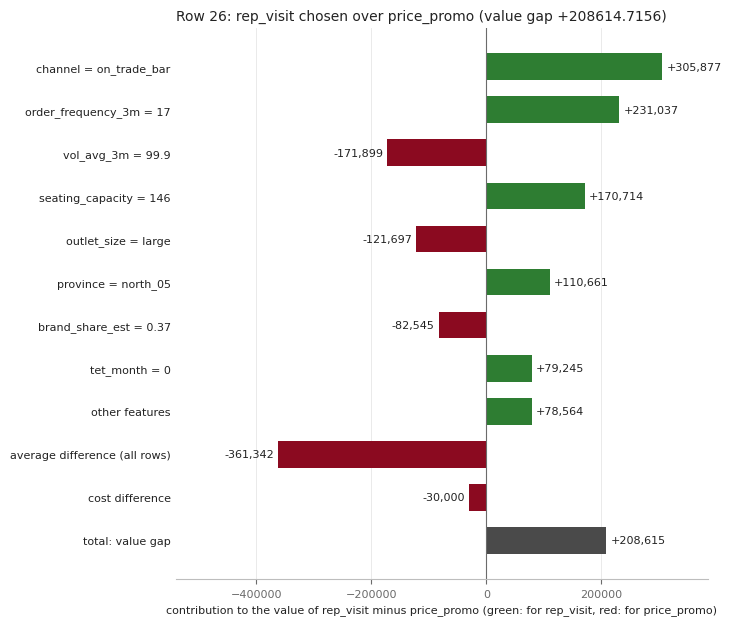

In [44]:
fig = it.plot_explain_row(row=row, policy=best)
# money in VND: whole numbers with thousands separators (the library prints 4 decimals)
import re as _re
_money = lambda m: f"{float(m.group(0)):+,.0f}"
for ax in fig.axes:
    for t in ax.texts:
        t.set_text(_re.sub(r"[+-]?\d+\.\d+", _money, t.get_text()))
    ax.set_title(_re.sub(r"[+-]\d+\.\d+", _money, ax.get_title()))
    lo, hi = ax.get_xlim(); ax.set_xlim(lo - 0.12 * (hi - lo), hi)
if fig._suptitle is not None:
    fig._suptitle.set_text(_re.sub(r"[+-]\d+\.\d+", _money, fig._suptitle.get_text()))
X.fig(fig, "explain_row",
      "explain_row: contribution of each feature to the net value gap between the chosen arm and the runner-up (VND).",
      "Part 11, MultiArmInterpreter.plot_explain_row()")

**How to read it.** One outlet-month: a large bar in the North, sales falling (`vol_trend_3m` -0.39),
brand share 0.37. Each bar is a feature's contribution to the gap in net value between the chosen arm and the
runner-up (`price_promo`). `average difference (all rows)` is the starting point: the model's average gap
between the two arms over the rows its trees were fitted on. It is strongly negative because those rows include
modern trade, where the model extrapolates rep visit effects far below zero (Part 13); the feature bars move
this outlet from that average to its own gap (+208,615 VND for the rep visit). It gets the rep visit because it
is a bar that orders often; its large volume pulls the other way. The rep-by-trend plot above shows the rep
effect largest where sales are falling and in bars and restaurants, as in the truth. The strongest interaction
printed earlier (`vol_avg_3m` with `channel`) is for `zalo_message`, an arm the model cannot rank (Part 9),
so it is not used.

**Takeaway.** The effects are driven by order_frequency_3m, vol_avg_3m, channel and n_coolers; the decisions by n_coolers, channel and vol_trend_3m (the only significant ones). The noise floor fails twice: the planted noise_feature passes it (ratio 1.88), and competitor_promo_active, a true promo driver in the data rules (data_rules.md), falls below it. noise_feature switches 6.3% of decisions with no significant value loss (CI -18,227 to 21,066), which only decision importance shows; that is not proof that it is harmless. Main weakness: the observed promo effect falls with brand share (8.1 cases at low share; point estimates below 0 above 0.62, with intervals that include 0), but the model's line only falls from 4.1 to 2.7 and stays above break-even. On the training outlets (out of fold, rows with evidence), the observed promo effect by band of brand share is (-0.001, 0.3] 5.0 (CI 3.2 to 6.9); (0.3, 0.45] 4.9 (CI 3.5 to 6.1); (0.45, 0.6] 2.1 (CI 1.1 to 3.2); (0.6, 0.7] 1.2 (CI -0.8 to 3.1); (0.7, 1.0] 2.0 (CI 0.2 to 3.7); missing 4.9 (CI 2.6 to 7.3) cases. Break-even is 2 cases: the promo pays clearly below 0.45, is near break-even from 0.45 to 0.6, and the bands above 0.6 are at or below break-even with intervals that cover 2. The training outlets support a cutoff near 0.6 only weakly: they do not show that the promo loses money above it, and the data alone does not pin the cutoff. The policy with the promo rule is therefore illustrative (Part 8).

## Part 12. Robustness checks

**Purpose.** Try to break the result. Each check has a pass rule and a meaning when it fails.

| Check | Question | Passes when |
|---|---|---|
| Overlap | Does every arm have evidence for every kind of outlet? | Every arm-channel cell with propensities below the floor is known and the policy gives no arm there |
| Clip sensitivity | Does the value depend on the propensity clip? | The gains change by less than their CI half-width across clips |
| Stability by month / channel | Does the gain hold in every month and channel? | No group where the model loses to the best single arm |
| Bootstrap | Do refits on subsamples choose the same arms? | No threshold was fixed in advance: descriptive only (5 refits, a rough check) |
| Placebo | With the arm column shuffled, does the gain vanish? | Real gain above every shuffled gain (p <= 0.05; with 19 shuffles 0.05 is the smallest possible p) |
| A/A | With an outcome the arm cannot change (last month's volume), does the model still find a gain? | No significant *positive* gain over all-control or over the best single arm. A negative gain is expected: on such an outcome every arm only costs money |
| Overfit | Are in-sample numbers far above the test numbers? | Out-of-fold and test close |

The checks run on the training outlets (refits, out of fold) except the overfit report, which also uses
the test outlets. Unless a cell says otherwise, the checks use every row, modern trade included, so effect
means and spreads (bootstrap `tau_mean`, A/A `tau_std`, overfit calibration slopes) are pulled by the large
extrapolated display and rep effects in modern trade, which no policy uses (Part 13).

In [45]:
rc = aum.MultiArmRobustnessChecker(model, ds_tr, method=METHOD, policy=best, n_boot=300, verbosity=0)
ov = rc.overlap(floor=h.PROPENSITY_FLOOR)
X.table(ov, "overlap", "Overlap per arm on the training outlets: estimated propensity distribution and share of rows below the floor.",
        "Part 12, MultiArmRobustnessChecker.overlap()")

,arm,arm_label,rows_given,share_given,e_p01,e_p05,e_median,share_below_floor,ess,ess_share,max_weight_share
0,0,control,24739,0.2945,0.1143,0.1256,0.3124,0.0000,"18,357.5313",0.7420,0.0001
1,1,zalo_message,13257,0.1578,0.1099,0.1192,0.1418,0.0000,"12,439.2496",0.9383,0.0001
2,2,price_promo,18630,0.2218,0.1180,0.1284,0.1511,0.0000,"14,829.9963",0.7960,0.0001
3,3,display_kit,13542,0.1612,0.0030,0.0056,0.1420,0.1031,"11,583.6796",0.8554,0.0002
4,4,rep_visit,13832,0.1647,0.0044,0.0077,0.1403,0.1030,"11,702.1324",0.8460,0.0001


*Columns.* `rows_given` and `share_given`: rows that received the arm in the data; `e_p01`, `e_p05`,
`e_median`: 1st and 5th percentile and median of the estimated propensity of the arm over all rows;
`share_below_floor`: rows below the floor (0.02); `ess` and `ess_share`: effective sample size of the inverse
propensity weights, and its share of the rows given the arm; `max_weight_share`: share of the total weight
carried by the single largest weight.

In [46]:
mt_low = pd.Series(model.training_frame(METHOD)[["e_3", "e_4"]].min(axis=1).to_numpy() < h.PROPENSITY_FLOOR).groupby(ds_tr.df.channel.to_numpy()).mean()
X.num(low_overlap_by_channel=mt_low.round(4).to_dict())
mt_low.rename("share of rows with e_display or e_rep below the floor")

modern_trade          1.0000
off_trade_grocery     0.0000
off_trade_minimart    0.0000
on_trade_bar          0.0000
on_trade_restaurant   0.0000
Name: share of rows with e_display or e_rep below the floor, dtype: float64

In [47]:
X.table(rc.clip_sensitivity(), "clip_sensitivity", "Clip sensitivity: DR value and gains (VND per outlet-month) for several propensity clips.",
        "Part 12, MultiArmRobustnessChecker.clip_sensitivity()")

,propensity_clip,value,value_ci_low,value_ci_high,gain_vs_best_single_arm,gain_vs_best_single_arm_ci_low,gain_vs_best_single_arm_ci_high,gain_vs_all_control,gain_vs_all_control_ci_low,gain_vs_all_control_ci_high,gain_vs_bau_rule,gain_vs_bau_rule_ci_low,gain_vs_bau_rule_ci_high
0,0.0010,"2,897,824.1712","2,839,581.8237","2,966,873.2680","178,322.1378","133,440.7785","215,914.8150","244,191.1880","197,468.9413","294,701.3639","27,217.9368","-6,972.6413","63,036.1058"
1,0.0050,"2,897,824.1712","2,839,581.8237","2,966,873.2680","178,322.1378","133,440.7785","215,914.8150","244,191.1880","197,468.9413","294,701.3639","27,217.9368","-6,972.6413","63,036.1058"
2,0.0100,"2,897,824.1712","2,839,581.8237","2,966,873.2680","178,322.1378","133,440.7785","215,914.8150","244,191.1880","197,468.9413","294,701.3639","27,217.9368","-6,972.6413","63,036.1058"
3,0.0200,"2,897,824.1712","2,839,581.8237","2,966,873.2680","178,322.1378","133,440.7785","215,914.8150","244,191.1880","197,468.9413","294,701.3639","27,217.9368","-6,972.6413","63,036.1058"
4,0.0500,"2,897,824.1712","2,839,581.8237","2,966,873.2680","178,322.1378","133,440.7785","215,914.8150","244,191.1880","197,468.9413","294,701.3639","27,217.9368","-6,972.6413","63,036.1058"


In [48]:
# month varies within an outlet, so it is passed by position (the training frame keeps the row order of ds_tr.df)
assert (model.training_frame(METHOD)["outlet_id"].to_numpy() == ds_tr.df["outlet_id"].to_numpy()).all()
st_m = rc.stability_by("month", values=ds_tr.df["month"].to_numpy(), freq="M")
X.table(st_m, "stability_month", "Stability by month: policy value and gains with 95% CI (VND per outlet-month).",
        "Part 12, MultiArmRobustnessChecker.stability_by('month')")

,group,n,share_arm_0,share_arm_1,share_arm_2,share_arm_3,share_arm_4,value,value_ci_low,value_ci_high,gain_vs_best_single_arm,gain_vs_best_single_arm_ci_low,gain_vs_best_single_arm_ci_high,gain_vs_all_control,gain_vs_all_control_ci_low,gain_vs_all_control_ci_high,gain_vs_bau_rule,gain_vs_bau_rule_ci_low,gain_vs_bau_rule_ci_high,model_loses
0,2026-01,14000,0.0384,0.0460,0.3397,0.1760,0.3999,"2,487,991.7335","2,395,279.2619","2,581,971.9736","177,250.8649","76,542.5194","284,643.4509","177,250.8649","76,542.5194","284,643.4509","68,346.6925","-5,801.7409","150,047.8763",False
1,2026-02,14000,0.0313,0.0364,0.2524,0.2152,0.4647,"3,925,960.0178","3,795,164.5837","4,064,521.7197","290,141.2221","185,372.1011","432,326.5794","451,787.9202","332,907.4884","593,106.1214","130,930.4281","35,236.3905","241,848.8713",False
2,2026-03,14000,0.0417,0.0616,0.3614,0.2093,0.3261,"2,557,542.7733","2,470,490.6141","2,664,419.4617","31,024.5666","-70,408.5994","125,685.3338","128,847.2399","26,293.3106","245,022.2976","-59,921.6981","-140,846.5201","24,414.0948",False
3,2026-04,14000,0.0394,0.0676,0.3297,0.1813,0.3819,"2,862,653.2827","2,759,034.1327","2,959,305.0752","195,224.1124","78,688.0052","296,705.2395","283,187.6072","165,469.5566","399,123.1790","50,909.7592","-46,775.7851","143,727.9317",False
4,2026-05,14000,0.0480,0.0542,0.2705,0.1704,0.4569,"2,748,543.0706","2,657,793.2650","2,853,771.9551","167,396.1130","78,236.7334","272,673.9314","217,765.7419","104,670.5231","325,849.0601","-3,891.2425","-86,407.3777","87,436.4553",False
5,2026-06,14000,0.0489,0.0663,0.3217,0.1887,0.3744,"2,804,254.1493","2,707,752.0249","2,908,978.0634","172,760.3524","82,378.4063","288,463.5176","206,307.7536","108,502.6816","333,989.1042","-23,066.3185","-118,541.5671","70,478.3459",False


In [49]:
st_c = rc.stability_by("channel")
X.num(model_loses_month=int(st_m["model_loses"].sum()), model_loses_channel=int(st_c["model_loses"].sum()))
X.table(st_c, "stability_channel", "Stability by channel: policy value and gains with 95% CI (VND per outlet-month).",
        "Part 12, MultiArmRobustnessChecker.stability_by('channel')")

,group,n,share_arm_0,share_arm_1,share_arm_2,share_arm_3,share_arm_4,value,value_ci_low,value_ci_high,gain_vs_best_single_arm,gain_vs_best_single_arm_ci_low,gain_vs_best_single_arm_ci_high,gain_vs_all_control,gain_vs_all_control_ci_low,gain_vs_all_control_ci_high,gain_vs_bau_rule,gain_vs_bau_rule_ci_low,gain_vs_bau_rule_ci_high,model_loses
0,modern_trade,8658,0.2253,0.1816,0.5931,0.0000,0.0000,"10,615,158.2819","10,289,052.4911","10,986,738.1605","-59,237.1032","-426,979.3728","251,312.9093","-59,237.1032","-426,979.3728","251,312.9093","-252,199.6620","-543,874.9532","40,290.3199",False
1,off_trade_grocery,27144,0.0174,0.0396,0.3662,0.3229,0.2539,"1,106,824.5897","1,070,643.3871","1,139,107.5194","123,699.1148","92,170.9608","153,921.2379","198,725.4548","162,074.5934","235,694.9131","71,860.8881","39,562.8923","98,391.2085",False
2,off_trade_minimart,15252,0.0113,0.0344,0.2611,0.3863,0.3069,"1,822,514.9811","1,761,287.6081","1,891,019.0772","155,848.3634","106,262.5728","215,151.5989","331,792.8220","246,536.7115","398,759.5826","52,548.2037",-846.9853,"108,169.8042",False
3,on_trade_bar,14766,0.0296,0.0493,0.1749,0.0359,0.7103,"3,092,615.8349","2,988,664.6386","3,217,930.8134","-82,380.9090","-154,189.3701","-5,597.7881","334,142.7173","230,570.4838","457,870.6397","95,089.7803","18,807.7590","174,437.4853",True
4,on_trade_restaurant,18180,0.0240,0.0412,0.2540,0.0432,0.6377,"2,640,537.9210","2,548,386.4830","2,734,952.9096","-59,786.9645","-121,157.5884",-969.0204,"310,026.1495","227,952.6715","402,454.0893","17,255.1441","-51,928.3330","77,203.9423",True


*Columns.* `share_arm_k`: share of the group's rows given arm k; `value`: DR policy value;
`gain_vs_best_single_arm`, `gain_vs_all_control`, `gain_vs_bau_rule` (with CIs): value minus that baseline on
the group's rows; `model_loses`: the CI of the gain over the best single arm lies entirely below 0.

In [50]:
bs = rc.bootstrap_cate(n_bootstrap=5)
X.num(bootstrap_agreement=bs["agreement"], bootstrap_n=bs["n_successful"])
print(f"bootstrap: {bs['n_successful']} refits on 80% subsamples; share of (row, refit) pairs with the original best arm: {bs['agreement']:.3f}")
X.table(bs["per_arm"], "bootstrap_per_arm", "Bootstrap (5 refits on 80% subsamples): per arm, mean CI width of the effect, share of rows whose CI excludes 0, "
        "correlation with the original effects.", "Part 12, MultiArmRobustnessChecker.bootstrap_cate()")

bootstrap: 5 refits on 80% subsamples; share of (row, refit) pairs with the original best arm: 0.772


,arm,comparison,tau_mean,mean_ci_width,share_ci_excludes_zero,mean_corr_with_original
0,1,zalo_message vs control,-0.2499,1.9980,0.1834,0.4067
1,2,price_promo vs control,3.1820,2.1877,0.8992,0.5528
2,3,display_kit vs control,-5.4025,6.4800,0.6982,0.9865
3,4,rep_visit vs control,-2.6481,5.5352,0.8892,0.9852


In [51]:
pl = rc.placebo_test(n_shuffles=19, max_rows=40_000)
X.num(placebo={k: v for k, v in pl.items() if k != "null_gains"}, placebo_null_max=float(np.max(pl["null_gains"])))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in pl.items() if k != "null_gains"})
print("largest shuffled gain:", round(float(np.max(pl["null_gains"]))))

{'actual_gain': 127932.2817, 'p_value': 0.05, 'significant': True, 'actual_tau_std': 21.4054, 'null_tau_std': 3.1146, 'n_successful': 19}
largest shuffled gain: 10316


In [52]:
# A/A: the outcome is last month's volume, which this month's arm cannot change.
ds_null = aum.UpliftDataset(ds_tr.df, treatment="arm", outcome="vol_last_1m",
                            features=[f for f in ds_tr.features if f != "vol_last_1m"], treatment_labels=LABELS,
                            date_col="month", rule_arm_col="rule_arm", id_cols=["outlet_id"], suppress_warnings=True)
aa = rc.aa_test(ds_null)
X.num(aa=aa)
aa

{'value': 2734579.8622,
 'value_ci_low': 2681877.2069,
 'value_ci_high': 2799690.7996,
 'gain_vs_best_single_arm': -57487.1908,
 'gain_vs_best_single_arm_ci_low': -91604.0907,
 'gain_vs_best_single_arm_ci_high': -20540.3301,
 'gain_vs_all_control': -33791.1419,
 'gain_vs_all_control_ci_low': -60190.3037,
 'gain_vs_all_control_ci_high': -2128.2039,
 'gain_vs_bau_rule': 65598.5908,
 'gain_vs_bau_rule_ci_low': 38937.133,
 'gain_vs_bau_rule_ci_high': 92787.5716,
 'passes': True,
 'tau_std': 20.526}

Overfit table: `gap` is in sample minus test; `reading` is the library's automatic label (the takeaway
below explains why the test column is not independent).

In [53]:
of = rc.overfit_report(ds_te)
X.table(of, "overfit", "Overfit report: the same metrics in sample, out of fold (training outlets) and on the test outlets.",
        "Part 12, MultiArmRobustnessChecker.overfit_report()")

,metric,in_sample,out_of_fold,test,test_ci_low,test_ci_high,gap,reading
0,policy_value,"3,056,313.3476","2,897,824.1712","2,849,977.8935","2,769,481.8195","2,958,533.8443","206,335.4541",
1,gain_vs_best_single_arm,"344,061.7270","178,322.1378","164,137.7485","98,902.4528","219,802.1947","179,923.9786",out-of-fold agrees with test; test gain proven
2,gain_vs_all_control,"404,815.3013","244,191.1880","251,665.9548","178,145.1353","318,486.9337","153,149.3465",out-of-fold agrees with test; test gain proven
3,gain_vs_bau_rule,"188,656.4193","27,217.9368","81,630.7028","27,310.5667","131,341.0297","107,025.7165",out-of-fold agrees with test; test gain proven
4,calibration_slope: zalo_message,4.8420,0.2065,0.5540,-0.8172,1.8654,4.2880,too noisy to judge on this many test rows (wide CI)
5,effect_std: zalo_message,1.7333,2.7770,1.7169,NaN,NaN,0.0164,
6,calibration_slope: price_promo,6.0107,0.5919,2.2337,0.2736,4.1091,3.7769,too noisy to judge on this many test rows (wide CI)
7,effect_std: price_promo,1.3929,2.2805,1.3345,NaN,NaN,0.0584,
8,calibration_slope: display_kit,1.1060,1.0103,1.0019,0.8668,1.1644,0.1041,consistent with 1: magnitudes about right
9,effect_std: display_kit,38.5006,39.0220,35.1938,NaN,NaN,3.3068,


In [54]:
print(rc.report(print_=False))

Robustness report (MultiArmRobustnessChecker)
  Learner: MultiArmLearner, method 'dr', 84,000 training rows, arms 0 = control, 1 = zalo_message, 2 = price_promo, 3 = display_kit, 4 = rep_visit
  Policy : MultiArmPolicy(value_per_outcome=60000, cost={0: 0, 1: 2000, 2: 120000, 3: 400000, 4: 150000}, propensity_floor=0.02)
  Out-of-fold policy value 2897824.1712; gain vs best single arm +178322.1378 [+133440.7785, +215914.8150]; vs BAU +27217.9368 [-6972.6413, +63036.1058]

  Overlap:
    control: given to 29.5%, e p01 0.114, below floor 0.0%, ESS share 0.74
    zalo_message: given to 15.8%, e p01 0.110, below floor 0.0%, ESS share 0.94
    price_promo: given to 22.2%, e p01 0.118, below floor 0.0%, ESS share 0.80
    display_kit: given to 16.1%, e p01 0.003, below floor 10.3%, ESS share 0.86  <- weak overlap
    rep_visit: given to 16.5%, e p01 0.004, below floor 10.3%, ESS share 0.85  <- weak overlap

  Clip sensitivity: gain vs best single arm ranges +178322.1378 to +178322.1378 over c

**Takeaway.** Pass or fail per check:

* Overlap: known and handled (display and rep have no evidence in modern trade; the policy keeps them out).
* Clip sensitivity: passes (identical value for every clip, which means no row's received arm has a propensity below the largest clip, 0.05).
* Stability by month: passes (March weakest, CI includes 0).
* Stability by channel: fails its own rule. The model loses significantly to rep visits for all in bars (-82,381 VND) and restaurants (-59,787), where it gives a promo to 17% and 25% of rows (training outlets, out of fold).
* Bootstrap: 77% agreement over 5 refits (each on an 80% subsample, agreement measured on 20,000 fixed rows). Descriptive only (no threshold fixed in advance; 5 refits is few). The negative tau_mean of display and rep comes from modern trade.
* Placebo: passes. Gain over the best single arm, out of fold, on a 40,000-row refit: real 127,932 VND against at most 10,316 for 19 shuffles; p = 0.05, the smallest p 19 shuffles allow.
* A/A: passes against all-control and the best single arm. Against BAU it shows +65,599 VND (CI 38,937 to 92,788) on an outcome no arm can change, because the A/A model spends little on arms (its loss against all-control is 33,791) while BAU spends about 94,000 VND per outlet-month on them; so BAU is not a valid baseline for this null check. model_best (about 184,000) and model_capacity (about 131,000) spend more than BAU as written, so the gain of model_best over BAU does not come from lower spending. The capped policies are compared with bau_within_limits (about 63,000), and all of them, model_top_share (about 72,000) included, spend more.
* Overfit: passes for out of fold and test (their intervals overlap); in sample is far too optimistic (188,656 over BAU); out of fold (27,218) and the test outlets (81,631, CI 27,311 to 131,341) are not inflated; they use different outlets and differ by about 54,000; their intervals overlap widely (out of fold CI -6,973 to 63,036). The test number is scored with the model's own outcome models, so it is not independent and its 'test gain proven' label should be read with Part 8's referee estimate (54,221, CI includes 0), which is the one to trust. The calibration slopes near 1 there include modern trade and are not evidence of good calibration (Part 10).

## Part 13. Model against the truth

**Purpose.** Grade the predicted effects on the test outlets against the true effects (only
possible with synthetic data): where the model is right, where it is wrong, by how much, and why.

**What to look at.** `bias` = mean predicted minus mean true effect (cases), `corr` = correlation
between predicted and true effects across rows. Large errors where an arm has no evidence
(modern trade never gets `display_kit` or `rep_visit`) are expected; the policy keeps those arms out.

In [55]:
mvt = h.model_vs_truth(frame_te, truth_te, df_te, meta)
X.num(model_vs_truth=mvt[mvt.channel == "all rows"].set_index("arm")[["mean_predicted", "mean_true", "bias", "corr"]].to_dict(orient="index"),
      modern_trade_pred={a: float(mvt[(mvt.arm == a) & (mvt.channel == "modern_trade")]["mean_predicted"].iloc[0]) for a in ["display_kit", "rep_visit"]})
X.table(mvt, "model_vs_truth", "Predicted against true effects on the test outlets (cases per outlet-month), per arm and channel.",
        "Part 13, h.model_vs_truth")

,arm,channel,rows,mean_predicted,mean_true,bias,corr
0,zalo_message,modern_trade,3480,-1.9900,0.4100,-2.4000,0.0600
1,zalo_message,on_trade_bar,6864,-0.2300,0.4000,-0.6300,0.0970
2,zalo_message,off_trade_minimart,6486,0.2300,0.4400,-0.2000,0.3260
3,zalo_message,off_trade_grocery,11388,0.0900,0.4200,-0.3200,0.3920
4,zalo_message,on_trade_restaurant,7782,-0.4100,0.5400,-0.9500,0.1020
5,zalo_message,all rows,36000,-0.2500,0.4400,-0.7000,0.1380
6,price_promo,modern_trade,3480,3.0900,5.0100,-1.9200,0.3760
7,price_promo,on_trade_bar,6864,3.1900,3.7800,-0.5900,0.3180
8,price_promo,off_trade_minimart,6486,3.4000,3.4600,-0.0600,0.5740
9,price_promo,off_trade_grocery,11388,3.1200,2.9000,0.2200,0.6650


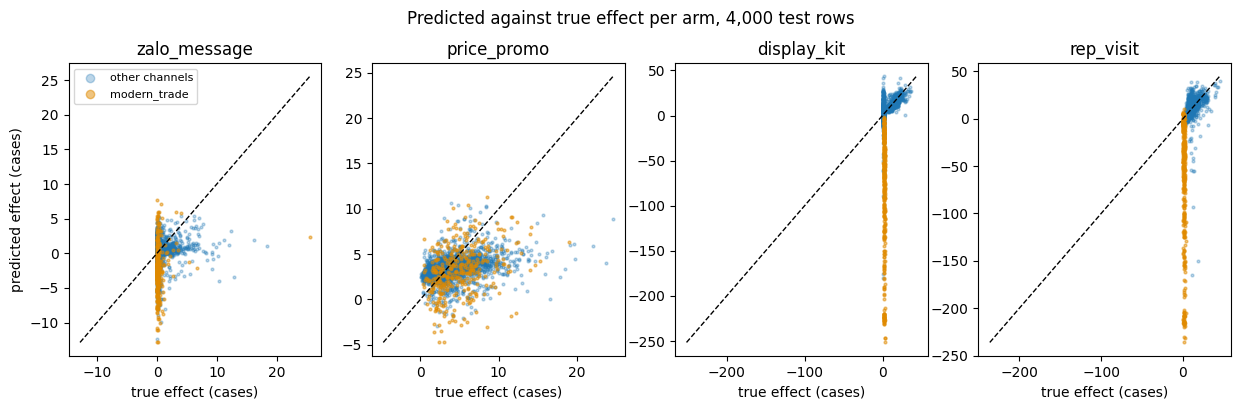

In [56]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
rs = np.random.default_rng(0).choice(len(frame_te), 4000, replace=False)
mt = (df_te.channel == "modern_trade").to_numpy()[rs]
for ax, k in zip(axes, range(1, 5)):
    p, t = frame_te[f"tau_{k}"].to_numpy()[rs], truth_te[f"tau_{k}"].to_numpy()[rs]
    ax.scatter(t[~mt], p[~mt], s=4, alpha=0.3, label="other channels")
    ax.scatter(t[mt], p[mt], s=4, alpha=0.5, color="#E08A00", label="modern_trade")
    lim = [min(t.min(), p.min()), max(t.max(), p.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(LABELS[k]); ax.set_xlabel("true effect (cases)")
axes[0].set_ylabel("predicted effect (cases)"); axes[0].legend(fontsize=8, markerscale=3)
fig.suptitle("Predicted against true effect per arm, 4,000 test rows", y=1.02)
X.fig(fig, "pred_vs_true", "Predicted (y) against true (x) effect per arm in cases per outlet-month, 4,000 random test rows; "
      "the dashed line is a perfect model.", "Part 13, matplotlib")

In [57]:
wrong = pd.DataFrame({"channel": df_te.channel, "chosen": pd.Series(arms_best).map(LABELS),
                      "true_best": truth_te.true_best_arm.map(LABELS),
                      "regret_vnd": net_te.max(1) - net_te[np.arange(n), arms_best]})
miss = wrong[wrong.chosen != wrong.true_best].groupby(["true_best", "chosen"]).agg(rows=("regret_vnd", "size"),
                                                                                    mean_regret_vnd=("regret_vnd", "mean"))
miss = miss.assign(mean_regret_vnd=miss.mean_regret_vnd.round(-2).astype(int)).sort_values("rows", ascending=False).head(8).reset_index()
X.num(mean_regret=float(wrong.regret_vnd.mean()), share_wrong=float((wrong.chosen != wrong.true_best).mean()),
      share_regret_small=float(((wrong.chosen != wrong.true_best) & (wrong.regret_vnd < 30_000)).sum() / max((wrong.chosen != wrong.true_best).sum(), 1)),
      regret_miss_quantiles={str(q): float(wrong.regret_vnd[wrong.chosen != wrong.true_best].quantile(q)) for q in (0.25, 0.5, 0.75)})
print("regret per wrong choice (VND per outlet-month), quartiles:",
      {q: round(float(wrong.regret_vnd[wrong.chosen != wrong.true_best].quantile(q))) for q in (0.25, 0.5, 0.75)})
X.table(miss, "misses", "Most frequent wrong choices on the test outlets: true best arm, arm chosen, rows and mean regret "
        "(true net value lost, VND per outlet-month).", "Part 13, pandas")

regret per wrong choice (VND per outlet-month), quartiles: {0.25: 36420, 0.5: 81153, 0.75: 160284}


,true_best,chosen,rows,mean_regret_vnd
0,rep_visit,price_promo,3028,116600
1,price_promo,rep_visit,1601,105900
2,zalo_message,price_promo,1552,89800
3,control,price_promo,1128,47500
4,price_promo,control,751,165900
5,display_kit,rep_visit,568,198200
6,rep_visit,display_kit,458,421900
7,price_promo,zalo_message,387,208800


**Takeaway.** Outside modern trade the display and rep effects are close to the truth in groceries and minimarts (bias at most about 0.3 cases, correlation 0.77 to 0.93). In bars and restaurants the rep effect is right on average but ranked less well (correlation 0.30 and 0.55), and the promo correlation there is about 0.31. In modern trade the model extrapolates display and rep effects of -86 and -71 cases, never used by the policy. The promo effect is right on average but poorly ranked (correlation 0.37). The zalo effect has the wrong sign on average (-0.25 predicted against +0.44 true). The model picks a different arm than the truth on 31% of rows; over all rows the mean regret is 43,115 VND per outlet-month, and per wrong choice the regret has quartiles 36,420, 81,153 and 160,284 VND: many misses are costly, not near-ties. The most common miss is a promo where a rep visit was best.

## What we conclude

* **Ranking.** The model ranks outlets for display kits and rep visits better than random
  targeting (Part 9, also on rows with evidence). For price promos the ranking is significant on all
  test rows but not on rows with evidence for every arm; for messages it is not shown.
* **Without caps** the model is estimated at 54,221 VND per outlet-month above BAU on the test
  outlets, but the interval includes zero. The model spends more on arms than BAU, so its gains are
  net of higher spending. The A/A test of Part 12 cannot check the comparison with BAU (BAU's arm
  costs alone put any cheap policy ahead of it on an outcome no arm can change).
* **Under the caps** the data cannot tell the model from BAU cut to the caps (-14,235, CI
  -83,586 to 57,084; with the promo rule 6,070, CI -63,936 to 72,631), although the truth
  favours the model by about 48,000 to 59,000 VND.
* **Failed check**: stability by channel. In bars and restaurants the model loses significantly to giving
  every outlet a rep visit (Part 12), likely because it gives promos there.
* **Main weakness**: the promo effect is too flat in brand share (Parts 2, 10 and 11; Part 13:
  promo correlation with the truth 0.37).
* **Next step**: a randomised pilot sized with the table of Part 8, analysed with the
  adjustment for pre-pilot features. At 9,000 outlets per side and 3 months it detects about 75,000 VND
  with 80% power. At the true advantages under the caps its power is about 44% (48,428) and 60%
  (58,987, with the promo rule). Reaching 80% power at about 50,000 VND would need about 20,000
  outlets per side, more than the outlet base, so no pilot on these outlets can detect a gain of that size reliably (80% power).
  The pilot is a way to collect randomised data under the new policy, with a stop rule for harm.

## Part 14. Reproduce

**Purpose.** Record what produced these numbers and save them for the reports.

The run needs the private library, so these commands work on the owner's machine only.
Without it, `pytest` (data generator tests) and `python build_case_study.py` (PDF from the
saved `outputs/`) still run.

```bash
python3.9 -m venv .venv && source .venv/bin/activate      # at the repository root
pip install -r case_study_beer/requirements.txt
cd case_study_beer
python -m data_gen.generate --out data/  # regenerates the synthetic data (also runs on its own)
python build_case_study.py --execute      # runs this notebook, then builds both PDFs
```

Seeds: data `random_state=42`, split seed 7, learners `random_state=0` (referee 1), tuner
`random_state=0`, bootstrap seed 0.

In [58]:
env = X.environment()
path = X.save()
print(f"saved outputs/{path.name} ({len(X.numbers)} entries) and {len(X.captions)} captions; runtime {X.numbers['runtime_seconds']} s")
env

saved outputs/case_study_numbers.json (77 entries) and 51 captions; runtime 1377 s


{'python': '3.9.13',
 'machine': 'arm64',
 'auto_uplift_multi_arms': '0.2.0',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'scikit-learn': '1.1.3',
 'lightgbm': '4.3.0',
 'optuna': '4.4.0',
 'scipy': '1.11.4',
 'matplotlib': '3.8.4'}

**Takeaway.** The run takes about 23 minutes. Every number used by the reports is in outputs/case_study_numbers.json and outputs/tables/.